# Patient Vitals Trajectory Prediction using Machine Learning

## Introduction

This notebook shows how to forecast a patient's **vital-sign trajectory** from bedside-monitor
data using machine learning.

### What We'll Build

A vitals forecasting system that can:
1. **Predict the next reading** of each monitored channel from the recent window
2. **Predict discharge disposition** from the first part of the stay
3. **Roll a forecast forward** over many steps to sketch the rest of the shift
4. **Compare a sequence model (LSTM) with a tabular model (XGBoost)**

### Dataset

We use **simulated bedside-monitor data** produced by `synthetic_vitals_generator.py`, which
samples every five minutes and records:
- Heart rate (bpm) and mean arterial pressure (mmHg)
- Oxygen saturation, SpO2 (%)
- Respiratory rate (breaths/min) and core temperature (deg C)
- Patient characteristics (age, sex, triage acuity)
- Minutes since admission, for temporal analysis

Each patient follows one of four clinical archetypes: **stable**, **post-operative recovery**,
**sepsis deterioration** and **cardiac event**.

> **About the data.** Every patient in this notebook is simulated from published physiological
> reference ranges. No real or identifiable patient information is used anywhere in this course.
> This notebook is one of only two that import a shared generator module rather than generating
> data inline, because both notebooks need the same multi-channel trajectories.

### Machine Learning Approaches

1. **Regression**: Predict the next value of each vital-sign channel
2. **Classification**: Predict discharge disposition
3. **Sequence Models**: LSTM for trajectory forecasting
4. **Feature Engineering**: Rate of change, rolling volatility and stay-progress features


## 1. Setup and Data Loading

In [1]:
# Core libraries
import sys
sys.path.append('../..')   # so we can import the shared vitals generator

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
from datetime import datetime, timedelta

# Machine learning
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, GradientBoostingRegressor
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import xgboost as xgb

# The shared simulator: bedside-monitor trajectories for a cohort of patients
from synthetic_vitals_generator import VitalsGenerator, ARCHETYPES, CHANNELS as VITAL_CHANNELS

warnings.filterwarnings('ignore')

# Visualization settings
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10

# One colour per channel, reused throughout the notebook
CHANNEL_COLORS = {
    'heart_rate': '#e74c3c',
    'map_mmhg': '#2980b9',
    'spo2': '#16a085',
    'resp_rate': '#8e44ad',
    'temp_c': '#e67e22',
}
CHANNEL_LABELS = {
    'heart_rate': 'Heart rate (bpm)',
    'map_mmhg': 'Mean arterial pressure (mmHg)',
    'spo2': 'SpO2 (%)',
    'resp_rate': 'Respiratory rate (/min)',
    'temp_c': 'Temperature (deg C)',
}
ARCHETYPE_COLORS = {
    'stable': '#27ae60',
    'post_op_recovery': '#2980b9',
    'sepsis_deterioration': '#e67e22',
    'cardiac_event': '#c0392b',
}

print("Libraries imported successfully")
print("Monitored channels:", VITAL_CHANNELS)


Libraries imported successfully
Monitored channels: ['heart_rate', 'map_mmhg', 'spo2', 'resp_rate', 'temp_c']


In [2]:
# Generate a cohort of simulated bedside-monitor trajectories.
# Sampling every 5 minutes for 24 hours gives 288 readings per patient.
SAMPLE_MINUTES = 5
STAY_HOURS = 24

generator = VitalsGenerator(seed=42, sample_minutes=SAMPLE_MINUTES)
df = generator.generate_cohort(n_patients=100, hours=STAY_HOURS)


def assign_dispositions(frame):
    """Derive a discharge disposition for every patient.

    The disposition follows from the patient's clinical archetype and from how
    they actually ended the stay: a sepsis patient whose pressure and saturation
    recovered goes to rehabilitation, one who is still decompensating is
    transferred to intensive care. This is the label a discharge planner would
    record, and it is what Section 6 asks the model to predict early.
    """
    dispositions = {}
    for pid, g in frame.groupby('patient_id', sort=False):
        archetype = g['archetype'].iloc[0]
        age = g['age'].iloc[0]
        tail = g.tail(12)                 # the last hour of monitoring
        end_hr = tail['heart_rate'].mean()
        end_map = tail['map_mmhg'].mean()
        end_spo2 = tail['spo2'].mean()

        if archetype == 'stable':
            disposition = 'Home with support' if age >= 80 else 'Home'
        elif archetype == 'post_op_recovery':
            disposition = 'Rehabilitation' if (age >= 78 or end_map < 80) else 'Home with support'
        elif archetype == 'sepsis_deterioration':
            disposition = 'ICU transfer' if (end_map < 72 or end_spo2 < 93) else 'Rehabilitation'
        else:  # cardiac_event
            disposition = 'Rehabilitation' if (end_hr < 92 and end_map > 80) else 'ICU transfer'
        dispositions[pid] = disposition

    return frame['patient_id'].map(dispositions)


df['disposition'] = assign_dispositions(df)

# Sort by patient and time, exactly as a monitoring export would be read
df = df.sort_values(['patient_id', 'minutes_since_admission']).reset_index(drop=True)

print("Simulated cohort generated (no real patient data)")
print(f"\nDataset Overview:")
print(f"  Total readings: {len(df):,}")
print(f"  Unique patients: {df['patient_id'].nunique():,}")
print(f"  Sampling interval: {SAMPLE_MINUTES} minutes")
print(f"  Stay length: {STAY_HOURS} hours ({df.groupby('patient_id').size().iloc[0]} readings per patient)")
print(f"  Clinical archetypes: {df['archetype'].nunique()}")
print(f"  Discharge dispositions: {df['disposition'].nunique()}")
print(f"\nArchetype mix:")
print(df.groupby('patient_id')['archetype'].first().value_counts().to_string())

df.head()


Simulated cohort generated (no real patient data)

Dataset Overview:
  Total readings: 28,800
  Unique patients: 100
  Sampling interval: 5 minutes
  Stay length: 24 hours (288 readings per patient)
  Clinical archetypes: 4
  Discharge dispositions: 4

Archetype mix:
archetype
stable                  39
sepsis_deterioration    23
post_op_recovery        23
cardiac_event           15


,patient_id,minutes_since_admission,heart_rate,map_mmhg,spo2,resp_rate,temp_c,timestamp,archetype,acuity,age,sex,deteriorating,disposition
0,P0000,0,84.488834,73.692918,95.437385,15.969714,36.509062,2026-01-01 00:00:00,sepsis_deterioration,3,47,F,0,ICU transfer
1,P0000,5,86.486996,70.231752,94.913362,14.283111,36.496009,2026-01-01 00:05:00,sepsis_deterioration,3,47,F,0,ICU transfer
2,P0000,10,87.720826,71.924111,94.690208,13.013438,36.412162,2026-01-01 00:10:00,sepsis_deterioration,3,47,F,0,ICU transfer
3,P0000,15,87.062219,75.956350,95.013868,13.855612,36.383863,2026-01-01 00:15:00,sepsis_deterioration,3,47,F,0,ICU transfer
4,P0000,20,88.941812,72.352228,95.867472,14.278918,36.371710,2026-01-01 00:20:00,sepsis_deterioration,3,47,F,0,ICU transfer


## 2. Exploratory Data Visualization

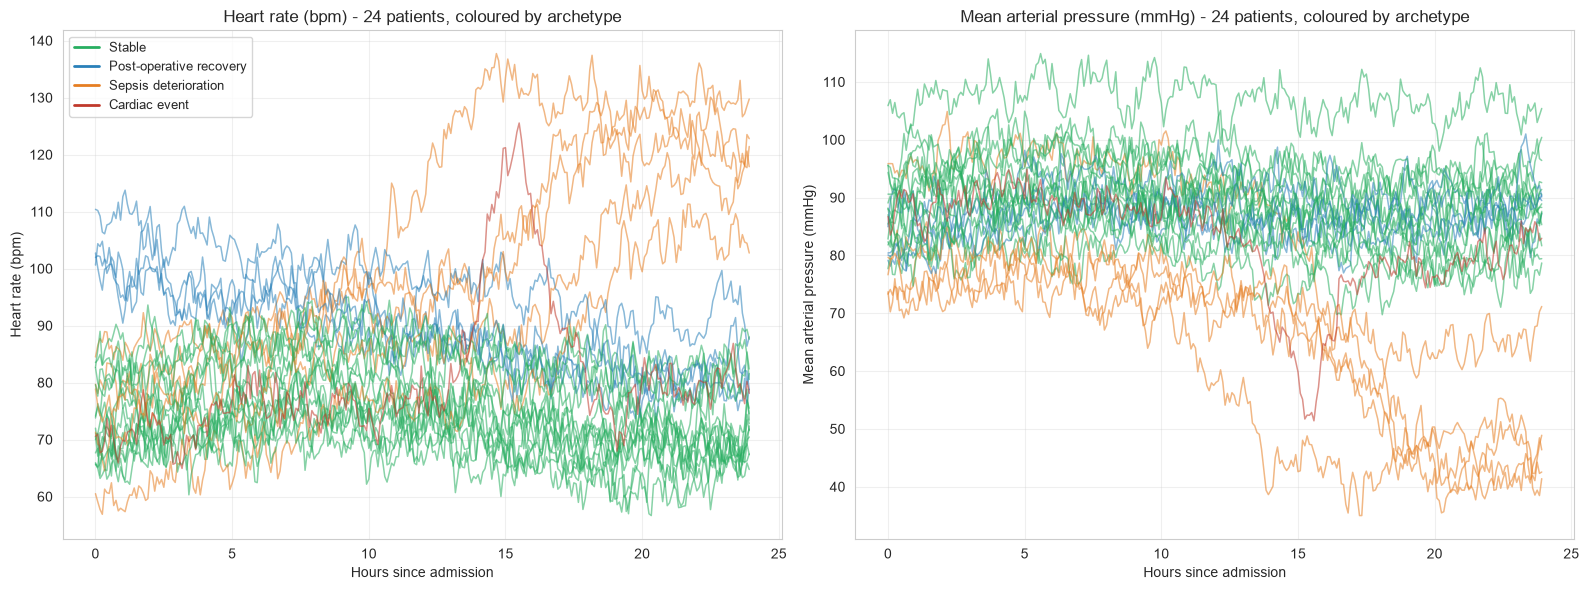

Every line is one patient's monitor trace over a 24-hour stay.
  Heart rate (bpm)                 range   50.1 to  150.8
  Mean arterial pressure (mmHg)    range   35.0 to  117.8
  SpO2 (%)                         range   86.2 to  100.0
  Respiratory rate (/min)          range    6.6 to   36.9
  Temperature (deg C)              range   35.7 to   39.0


In [3]:
# Cohort overview: the two channels we will forecast, one line per patient
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sample_patients = df['patient_id'].unique()[:24]

for ax, channel in zip(axes, ['heart_rate', 'map_mmhg']):
    for pid in sample_patients:
        pdata = df[df['patient_id'] == pid]
        archetype = pdata['archetype'].iloc[0]
        ax.plot(pdata['minutes_since_admission'] / 60,
                pdata[channel],
                color=ARCHETYPE_COLORS[archetype],
                alpha=0.55, linewidth=1.1)
    ax.set_xlabel('Hours since admission')
    ax.set_ylabel(CHANNEL_LABELS[channel])
    ax.set_title(f'{CHANNEL_LABELS[channel]} - 24 patients, coloured by archetype')
    ax.grid(alpha=0.3)

# One shared legend for the archetypes
handles = [plt.Line2D([0], [0], color=c, linewidth=2, label=ARCHETYPES[a]['label'])
           for a, c in ARCHETYPE_COLORS.items()]
axes[0].legend(handles=handles, loc='upper left', fontsize=9)

plt.tight_layout()
plt.show()

print("Every line is one patient's monitor trace over a 24-hour stay.")
for channel in VITAL_CHANNELS:
    print(f"  {CHANNEL_LABELS[channel]:32s} range {df[channel].min():6.1f} to {df[channel].max():6.1f}")


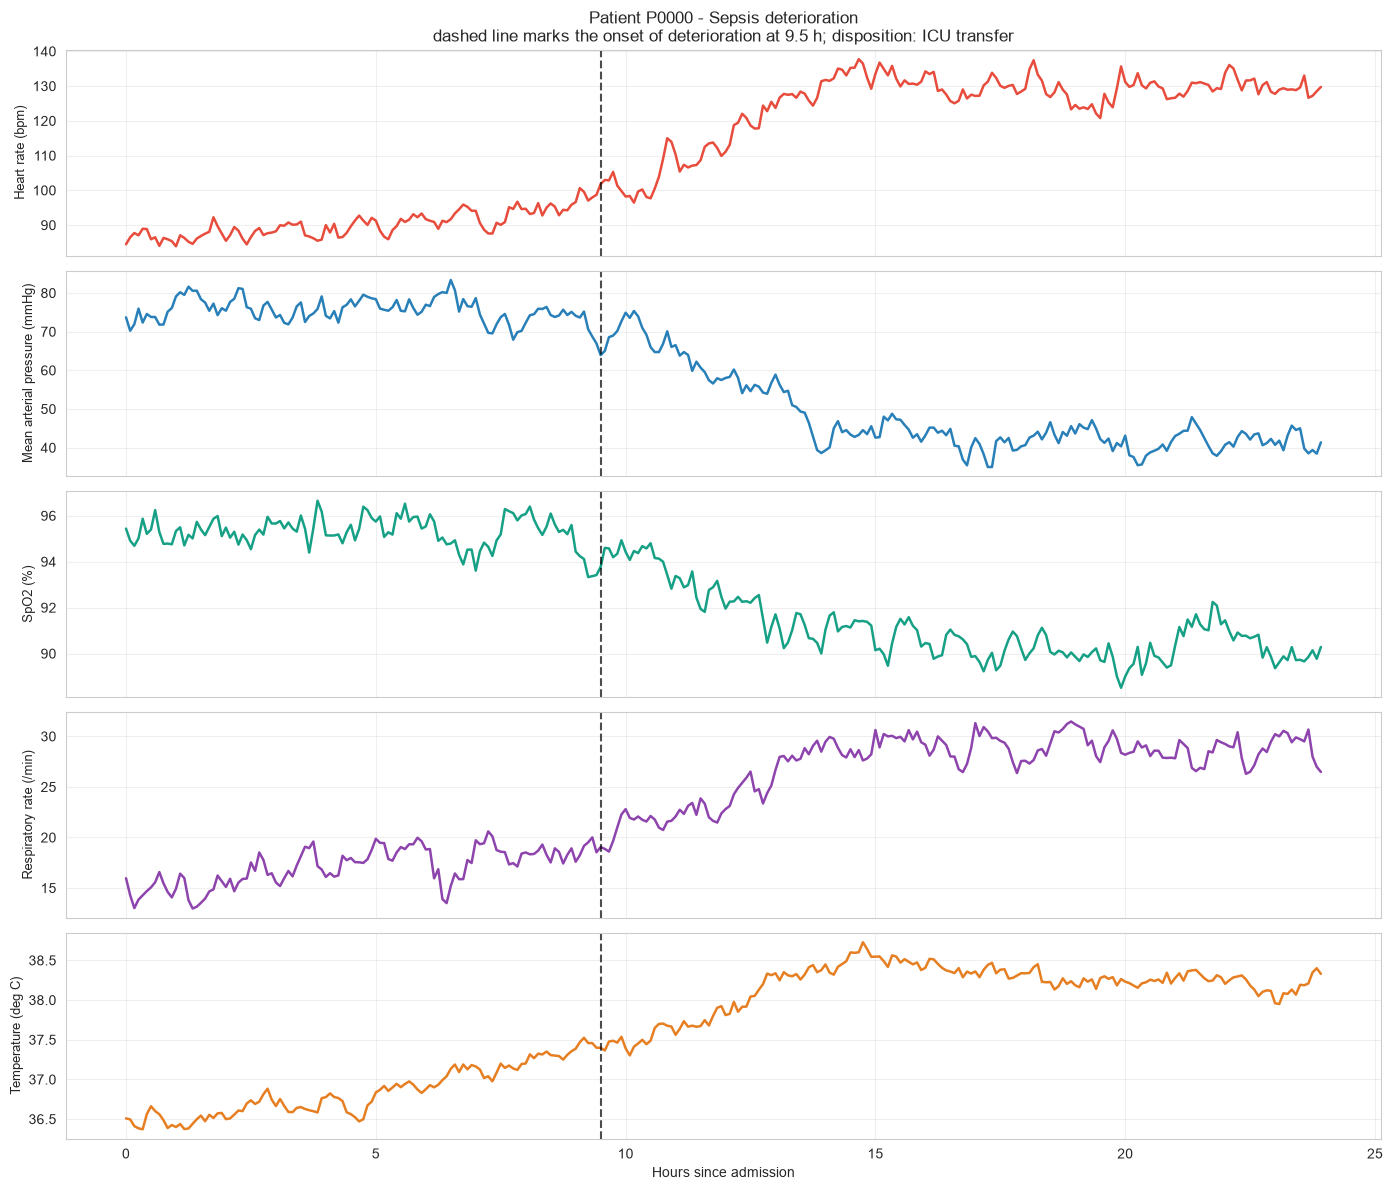

Patient P0000 statistics:
  Archetype: Sepsis deterioration
  Age / sex / acuity: 47 / F / 3
  Total readings: 288
  Mean heart rate: 111.1 bpm
  Peak heart rate: 137.7 bpm
  Lowest mean arterial pressure: 35.0 mmHg
  Stay length: 23.9 hours


In [4]:
# Detailed view of a single patient: every channel, with the deterioration onset marked
deteriorating_patients = df[df['deteriorating'] == 1]['patient_id'].unique()
sample_patient = deteriorating_patients[0]
patient_df = df[df['patient_id'] == sample_patient].copy()

hours = patient_df['minutes_since_admission'] / 60
onset_hours = patient_df.loc[patient_df['deteriorating'] == 1, 'minutes_since_admission'].min() / 60

fig, axes = plt.subplots(len(VITAL_CHANNELS), 1, figsize=(14, 12), sharex=True)

for ax, channel in zip(axes, VITAL_CHANNELS):
    ax.plot(hours, patient_df[channel], color=CHANNEL_COLORS[channel], linewidth=1.8)
    ax.axvline(onset_hours, color='black', linestyle='--', linewidth=1.5, alpha=0.7)
    ax.set_ylabel(CHANNEL_LABELS[channel], fontsize=9)
    ax.grid(alpha=0.3)

axes[0].set_title(
    f"Patient {sample_patient} - {ARCHETYPES[patient_df['archetype'].iloc[0]]['label']}\n"
    f"dashed line marks the onset of deterioration at {onset_hours:.1f} h; "
    f"disposition: {patient_df['disposition'].iloc[0]}"
)
axes[-1].set_xlabel('Hours since admission')

plt.tight_layout()
plt.show()

print(f"Patient {sample_patient} statistics:")
print(f"  Archetype: {ARCHETYPES[patient_df['archetype'].iloc[0]]['label']}")
print(f"  Age / sex / acuity: {patient_df['age'].iloc[0]} / {patient_df['sex'].iloc[0]} / {patient_df['acuity'].iloc[0]}")
print(f"  Total readings: {len(patient_df)}")
print(f"  Mean heart rate: {patient_df['heart_rate'].mean():.1f} bpm")
print(f"  Peak heart rate: {patient_df['heart_rate'].max():.1f} bpm")
print(f"  Lowest mean arterial pressure: {patient_df['map_mmhg'].min():.1f} mmHg")
print(f"  Stay length: {patient_df['minutes_since_admission'].max() / 60:.1f} hours")


## 3. A Balanced Cohort

**Purpose**: drawn at their natural prevalence, the two archetypes that actually deteriorate -
sepsis and cardiac event - make up only about a third of the cohort. To compare an LSTM against
XGBoost fairly we want plenty of trajectories that contain:
- A clear turning point (the onset of deterioration)
- Channels that move in opposite directions (heart rate up, pressure down)
- Recovery as well as decline

Run the next cell to replace the naturally-sampled cohort with a balanced one.

### The four clinical archetypes

| Archetype | What the monitor shows |
|---|---|
| **Stable** | Vitals hold near the patient's own baseline for the whole stay |
| **Post-operative recovery** | Perturbed at admission, settling back toward baseline |
| **Sepsis deterioration** | A slow early drift that steepens into fever, tachycardia and falling pressure |
| **Cardiac event** | A long quiet period, then an abrupt short crisis with partial recovery |

A balanced cohort holds one quarter of each, so every archetype is well represented in both the
training and the test split.

In [5]:
# ============================================================================
# Balanced Cohort Generator
# ============================================================================
# Set USE_BALANCED_COHORT = True to draw an equal number of each archetype.
# This replaces the naturally-sampled cohort with one that has plenty of
# deterioration events for the models to learn from.

USE_BALANCED_COHORT = True  # Toggle this to switch between natural / balanced mix

if USE_BALANCED_COHORT:
    print("Generating a BALANCED cohort with all four clinical archetypes...")
    print("=" * 60)

    balanced_generator = VitalsGenerator(seed=42, sample_minutes=SAMPLE_MINUTES)
    df = balanced_generator.generate_cohort(
        n_patients=120,
        hours=STAY_HOURS,
        archetypes=list(ARCHETYPES),   # cycles stable / post-op / sepsis / cardiac
    )
    df['disposition'] = assign_dispositions(df)
    df = df.sort_values(['patient_id', 'minutes_since_admission']).reset_index(drop=True)

    print(f"Generated {len(df):,} readings for {df['patient_id'].nunique()} patients")
    print(f"  Each stay is {STAY_HOURS} h sampled every {SAMPLE_MINUTES} min")
    print(f"  Deterioration events are present in half the cohort")

    print("\nArchetype mix:")
    print(df.groupby('patient_id')['archetype'].first().value_counts().to_string())

    print("\nDischarge dispositions:")
    print(df.groupby('patient_id')['disposition'].first().value_counts().to_string())

    # How sharply do the vitals actually move?
    sample = df[df['patient_id'] == df.loc[df['archetype'] == 'sepsis_deterioration', 'patient_id'].iloc[0]]
    hr_step = np.abs(np.diff(sample['heart_rate'].values))
    print("\nSample sepsis trajectory, step-to-step change in heart rate:")
    print(f"  Largest 5-minute change: {hr_step.max():.1f} bpm")
    print(f"  Steps changing more than 3 bpm: {(hr_step > 3).sum()}")

else:
    print("Using the NATURALLY SAMPLED cohort (40% stable, 25% post-op, 20% sepsis, 15% cardiac)")
    print("Set USE_BALANCED_COHORT = True for an equal mix of the four archetypes")


Generating a BALANCED cohort with all four clinical archetypes...
Generated 34,560 readings for 120 patients
  Each stay is 24 h sampled every 5 min
  Deterioration events are present in half the cohort

Archetype mix:
archetype
stable                  30
post_op_recovery        30
sepsis_deterioration    30
cardiac_event           30

Discharge dispositions:
disposition
ICU transfer         45
Rehabilitation       26
Home                 25
Home with support    24

Sample sepsis trajectory, step-to-step change in heart rate:
  Largest 5-minute change: 6.5 bpm
  Steps changing more than 3 bpm: 63


## 4. Feature Engineering

Turn the raw monitor stream into features a model can use.

Trajectory forecasting needs more than the current reading. It needs to know how fast each
channel is moving, how settled the patient is, and how far they are from their own normal:

| Feature | What it captures |
|---|---|
| **Rate of change** per channel (`d_*`) | How fast a vital sign is moving, per 5-minute step |
| **Rolling volatility** per channel (`roll_std_*`) | How unsettled the patient is over the last 30 minutes |
| **Deviation from admission baseline** (`dev_*`) | How far from this particular patient's normal |
| **Stay progress** | Where we are in the monitored period, 0 to 1 |
| **Minutes since admission** | Absolute time on the ward |

In [6]:
def engineer_features(df):
    """
    Create features for vitals forecasting models.

    Features include:
    - Temporal: hour of day, hours since admission, stay progress
    - Level: deviation from the patient's own admission baseline
    - Movement: rate of change per channel (the clinical analogue of speed)
    - Stability: rolling mean and rolling volatility (the analogue of course steadiness)
    - Historical: the previous reading and the previous rate of change
    """
    df_feat = df.sort_values(['patient_id', 'minutes_since_admission']).reset_index(drop=True)

    # Temporal features
    df_feat['hours_since_admission'] = df_feat['minutes_since_admission'] / 60.0
    df_feat['hour_of_day'] = df_feat['timestamp'].dt.hour
    df_feat['is_night'] = ((df_feat['hour_of_day'] < 6) | (df_feat['hour_of_day'] >= 22)).astype(int)

    # Stay progress (0 at admission, 1 at the end of the monitored period)
    df_feat['stay_progress'] = df_feat.groupby('patient_id')['minutes_since_admission'].transform(
        lambda s: s / s.max()
    )

    # Per-channel features
    for channel in VITAL_CHANNELS:
        grouped = df_feat.groupby('patient_id')[channel]

        # Lagged value (previous monitor reading)
        df_feat[f'prev_{channel}'] = grouped.shift(1)

        # Rate of change: how fast the channel is moving, per 5-minute step.
        # This is the clinical analogue of speed over ground.
        df_feat[f'd_{channel}'] = grouped.diff()

        # Rolling statistics over the last 30 minutes (6 readings)
        df_feat[f'roll_mean_{channel}'] = grouped.transform(
            lambda s: s.rolling(window=6, min_periods=1).mean()
        )
        # Rolling volatility: how unsettled the channel is.
        # This is the clinical analogue of turn rate.
        df_feat[f'roll_std_{channel}'] = grouped.transform(
            lambda s: s.rolling(window=6, min_periods=1).std()
        )

        # The patient's own admission baseline (first 30 minutes) and the
        # current deviation from it. Deviation is a RELATIVE level feature:
        # it says how far from normal this patient is, not what the raw number is.
        baseline = grouped.transform(lambda s: s.iloc[:6].mean())
        df_feat[f'baseline_{channel}'] = baseline
        df_feat[f'dev_{channel}'] = df_feat[channel] - baseline

    # Previous rate of change for the two channels we forecast
    for channel in ('heart_rate', 'map_mmhg'):
        df_feat[f'prev_d_{channel}'] = df_feat.groupby('patient_id')[f'd_{channel}'].shift(1)

    # Encode sex
    df_feat['sex_encoded'] = (df_feat['sex'] == 'M').astype(int)

    # Fill NaN values produced by the shifts and diffs
    df_feat = df_feat.bfill().fillna(0)

    return df_feat

# Apply feature engineering
print("Engineering features...")
df_features = engineer_features(df)
print(f"Created {len(df_features.columns)} columns")

# Display sample features
feature_cols = ['hour_of_day', 'stay_progress', 'hours_since_admission', 'dev_heart_rate',
                'dev_map_mmhg', 'd_heart_rate', 'roll_std_heart_rate', 'roll_mean_map_mmhg']
print("\nSample engineered features:")
df_features[['patient_id', 'heart_rate', 'map_mmhg', 'spo2'] + feature_cols].head(10)


Engineering features...


Created 51 columns

Sample engineered features:


,patient_id,heart_rate,map_mmhg,spo2,hour_of_day,stay_progress,hours_since_admission,dev_heart_rate,dev_map_mmhg,d_heart_rate,roll_std_heart_rate,roll_mean_map_mmhg
0,P0000,82.777812,94.305717,94.658758,0,0.000000,0.000000,-1.196189,1.030891,-1.813210,1.282133,94.305717
1,P0000,80.964602,93.614165,95.562995,0,0.003484,0.083333,-3.009399,0.339339,-1.813210,1.282133,93.959941
2,P0000,83.489149,90.361598,94.787310,0,0.006969,0.166667,-0.484852,-2.913229,2.524547,1.301734,92.760493
3,P0000,85.102201,92.204215,94.382956,0,0.010453,0.250000,1.128200,-1.070612,1.613052,1.714923,92.621424
4,P0000,84.716849,96.344698,94.576149,0,0.013937,0.333333,0.742849,3.069872,-0.385351,1.655090,93.366079
5,P0000,86.793392,92.818565,95.335810,0,0.017422,0.416667,2.819391,-0.456261,2.076542,2.024651,93.274826
6,P0000,86.856621,95.090316,94.609203,0,0.020906,0.500000,2.882620,1.815489,0.063230,2.218193,93.405593
7,P0000,84.002899,94.356495,94.749680,0,0.024390,0.583333,0.028898,1.081668,-2.853722,1.405478,93.529314
8,P0000,84.669810,94.377800,95.559836,0,0.027875,0.666667,0.695809,1.102974,0.666910,1.191018,94.198681
9,P0000,82.249256,92.425270,94.581759,0,0.031359,0.750000,-1.724745,-0.849556,-2.420554,1.750943,94.235524


## 5. Task 1: Next-Reading Prediction (Regression)

Predict the next value of each monitored channel given the patient's current state.

In [7]:
# Prepare data for regression: predict the NEXT reading of each channel
# Target: the next monitor sample (shift -1)
df_reg = df_features.copy()

for channel in VITAL_CHANNELS:
    df_reg[f'next_{channel}'] = df_reg.groupby('patient_id')[channel].shift(-1)

# Remove the last reading for each patient (no next reading exists)
df_reg = df_reg.dropna(subset=[f'next_{c}' for c in VITAL_CHANNELS])

# Select features for the model.
# NOTE: We deliberately EXCLUDE the raw current heart_rate and map_mmhg, and their
# lagged values, to avoid 'cheating'. Feeding the model the current reading of the
# channel it is asked to predict makes the task trivial (R2 > 0.999) at a 5-minute
# horizon. Instead we predict from the other channels, the movement pattern, and
# the deviation from the patient's own baseline.
feature_columns = [
    # The other monitored channels, which we are not predicting here
    'spo2', 'resp_rate', 'temp_c',
    # Patient characteristics
    'age', 'acuity', 'sex_encoded', 'baseline_heart_rate', 'baseline_map_mmhg',
    # Temporal features
    'hour_of_day', 'is_night', 'stay_progress', 'hours_since_admission',
    # Relative level (deviation from this patient's own baseline, not the raw value)
    'dev_heart_rate', 'dev_map_mmhg',
    # Movement: rates of change capture the direction of travel
    'prev_d_heart_rate', 'prev_d_map_mmhg',
    'd_heart_rate', 'd_map_mmhg', 'd_spo2', 'd_resp_rate',
    # Rolling statistics: level and volatility over the last 30 minutes
    'roll_mean_heart_rate', 'roll_std_heart_rate', 'roll_std_map_mmhg',
]

X = df_reg[feature_columns]
y_hr = df_reg['next_heart_rate']
y_map = df_reg['next_map_mmhg']

# Train/test split (80/20)
X_train, X_test, y_hr_train, y_hr_test, y_map_train, y_map_test = train_test_split(
    X, y_hr, y_map, test_size=0.2, random_state=42
)

print(f"Regression Dataset:")
print(f"  Training samples: {len(X_train):,}")
print(f"  Test samples: {len(X_test):,}")
print(f"  Features: {len(feature_columns)}")
print(f"  Primary targets: next_heart_rate, next_map_mmhg")
print(f"\n  NOTE: raw heart_rate / map_mmhg excluded from features to avoid 'cheating'")


Regression Dataset:
  Training samples: 27,552
  Test samples: 6,888
  Features: 23
  Primary targets: next_heart_rate, next_map_mmhg

  NOTE: raw heart_rate / map_mmhg excluded from features to avoid 'cheating'


In [8]:
# Train models for heart rate and mean arterial pressure
print("Training next-reading prediction models...\n")

# Model 1: Random Forest for heart rate
print("1. Training Random Forest for heart rate...")
rf_hr = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_hr.fit(X_train, y_hr_train)
y_hr_pred_rf = rf_hr.predict(X_test)
print(f"   Heart rate MAE: {mean_absolute_error(y_hr_test, y_hr_pred_rf):.3f} bpm")
print(f"   Heart rate RMSE: {np.sqrt(mean_squared_error(y_hr_test, y_hr_pred_rf)):.3f} bpm")
print(f"   Heart rate R2: {r2_score(y_hr_test, y_hr_pred_rf):.4f}")

# Model 2: Random Forest for mean arterial pressure
print("\n2. Training Random Forest for mean arterial pressure...")
rf_map = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_map.fit(X_train, y_map_train)
y_map_pred_rf = rf_map.predict(X_test)
print(f"   Pressure MAE: {mean_absolute_error(y_map_test, y_map_pred_rf):.3f} mmHg")
print(f"   Pressure RMSE: {np.sqrt(mean_squared_error(y_map_test, y_map_pred_rf)):.3f} mmHg")
print(f"   Pressure R2: {r2_score(y_map_test, y_map_pred_rf):.4f}")

# Model 3: XGBoost for heart rate
print("\n3. Training XGBoost for heart rate...")
xgb_hr = xgb.XGBRegressor(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
xgb_hr.fit(X_train, y_hr_train, verbose=False)
y_hr_pred_xgb = xgb_hr.predict(X_test)
print(f"   Heart rate MAE: {mean_absolute_error(y_hr_test, y_hr_pred_xgb):.3f} bpm")
print(f"   Heart rate R2: {r2_score(y_hr_test, y_hr_pred_xgb):.4f}")

# Model 4: XGBoost for mean arterial pressure
print("\n4. Training XGBoost for mean arterial pressure...")
xgb_map = xgb.XGBRegressor(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
xgb_map.fit(X_train, y_map_train, verbose=False)
y_map_pred_xgb = xgb_map.predict(X_test)
print(f"   Pressure MAE: {mean_absolute_error(y_map_test, y_map_pred_xgb):.3f} mmHg")
print(f"   Pressure R2: {r2_score(y_map_test, y_map_pred_xgb):.4f}")

# The remaining channels, so that every monitored channel gets a forecast
print("\n5. Training XGBoost for the remaining channels...")
CHANNEL_UNITS = {'heart_rate': 'bpm', 'map_mmhg': 'mmHg', 'spo2': '%',
                 'resp_rate': '/min', 'temp_c': 'deg C'}
channel_models = {'heart_rate': xgb_hr, 'map_mmhg': xgb_map}
channel_scores = {}

for channel in VITAL_CHANNELS:
    y_ch = df_reg[f'next_{channel}']
    y_ch_train, y_ch_test = y_ch.loc[X_train.index], y_ch.loc[X_test.index]
    if channel not in channel_models:
        m = xgb.XGBRegressor(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
        m.fit(X_train, y_ch_train, verbose=False)
        channel_models[channel] = m
    pred = channel_models[channel].predict(X_test)
    channel_scores[channel] = {
        'MAE': mean_absolute_error(y_ch_test, pred),
        'R2': r2_score(y_ch_test, pred),
    }

# Combined error across the two primary channels
hr_error_rf = np.abs(y_hr_test - y_hr_pred_rf)
map_error_rf = np.abs(y_map_test - y_map_pred_rf)
hr_error_xgb = np.abs(y_hr_test - y_hr_pred_xgb)
map_error_xgb = np.abs(y_map_test - y_map_pred_xgb)

print("\n" + "=" * 70)
print("NEXT-READING PREDICTION SUMMARY (5 minutes ahead)")
print("=" * 70)
print(f"{'Channel':<24} {'MAE':>10} {'unit':>8} {'R2':>8}")
print("-" * 70)
for channel, s in channel_scores.items():
    print(f"{CHANNEL_LABELS[channel]:<24} {s['MAE']:>10.3f} {CHANNEL_UNITS[channel]:>8} {s['R2']:>8.4f}")
print("-" * 70)
print(f"Random Forest - heart rate {hr_error_rf.mean():.2f} bpm, pressure {map_error_rf.mean():.2f} mmHg")
print(f"XGBoost       - heart rate {hr_error_xgb.mean():.2f} bpm, pressure {map_error_xgb.mean():.2f} mmHg")
print("=" * 70)


Training next-reading prediction models...

1. Training Random Forest for heart rate...


   Heart rate MAE: 2.089 bpm
   Heart rate RMSE: 2.632 bpm
   Heart rate R2: 0.9758

2. Training Random Forest for mean arterial pressure...


   Pressure MAE: 1.693 mmHg
   Pressure RMSE: 2.131 mmHg
   Pressure R2: 0.9742

3. Training XGBoost for heart rate...


   Heart rate MAE: 2.025 bpm
   Heart rate R2: 0.9774

4. Training XGBoost for mean arterial pressure...


   Pressure MAE: 1.672 mmHg
   Pressure R2: 0.9751

5. Training XGBoost for the remaining channels...



NEXT-READING PREDICTION SUMMARY (5 minutes ahead)
Channel                         MAE     unit       R2
----------------------------------------------------------------------
Heart rate (bpm)              2.025      bpm   0.9774
Mean arterial pressure (mmHg)      1.672     mmHg   0.9751
SpO2 (%)                      0.382        %   0.9460
Respiratory rate (/min)       0.759     /min   0.9571
Temperature (deg C)           0.052    deg C   0.9879
----------------------------------------------------------------------
Random Forest - heart rate 2.09 bpm, pressure 1.69 mmHg
XGBoost       - heart rate 2.02 bpm, pressure 1.67 mmHg


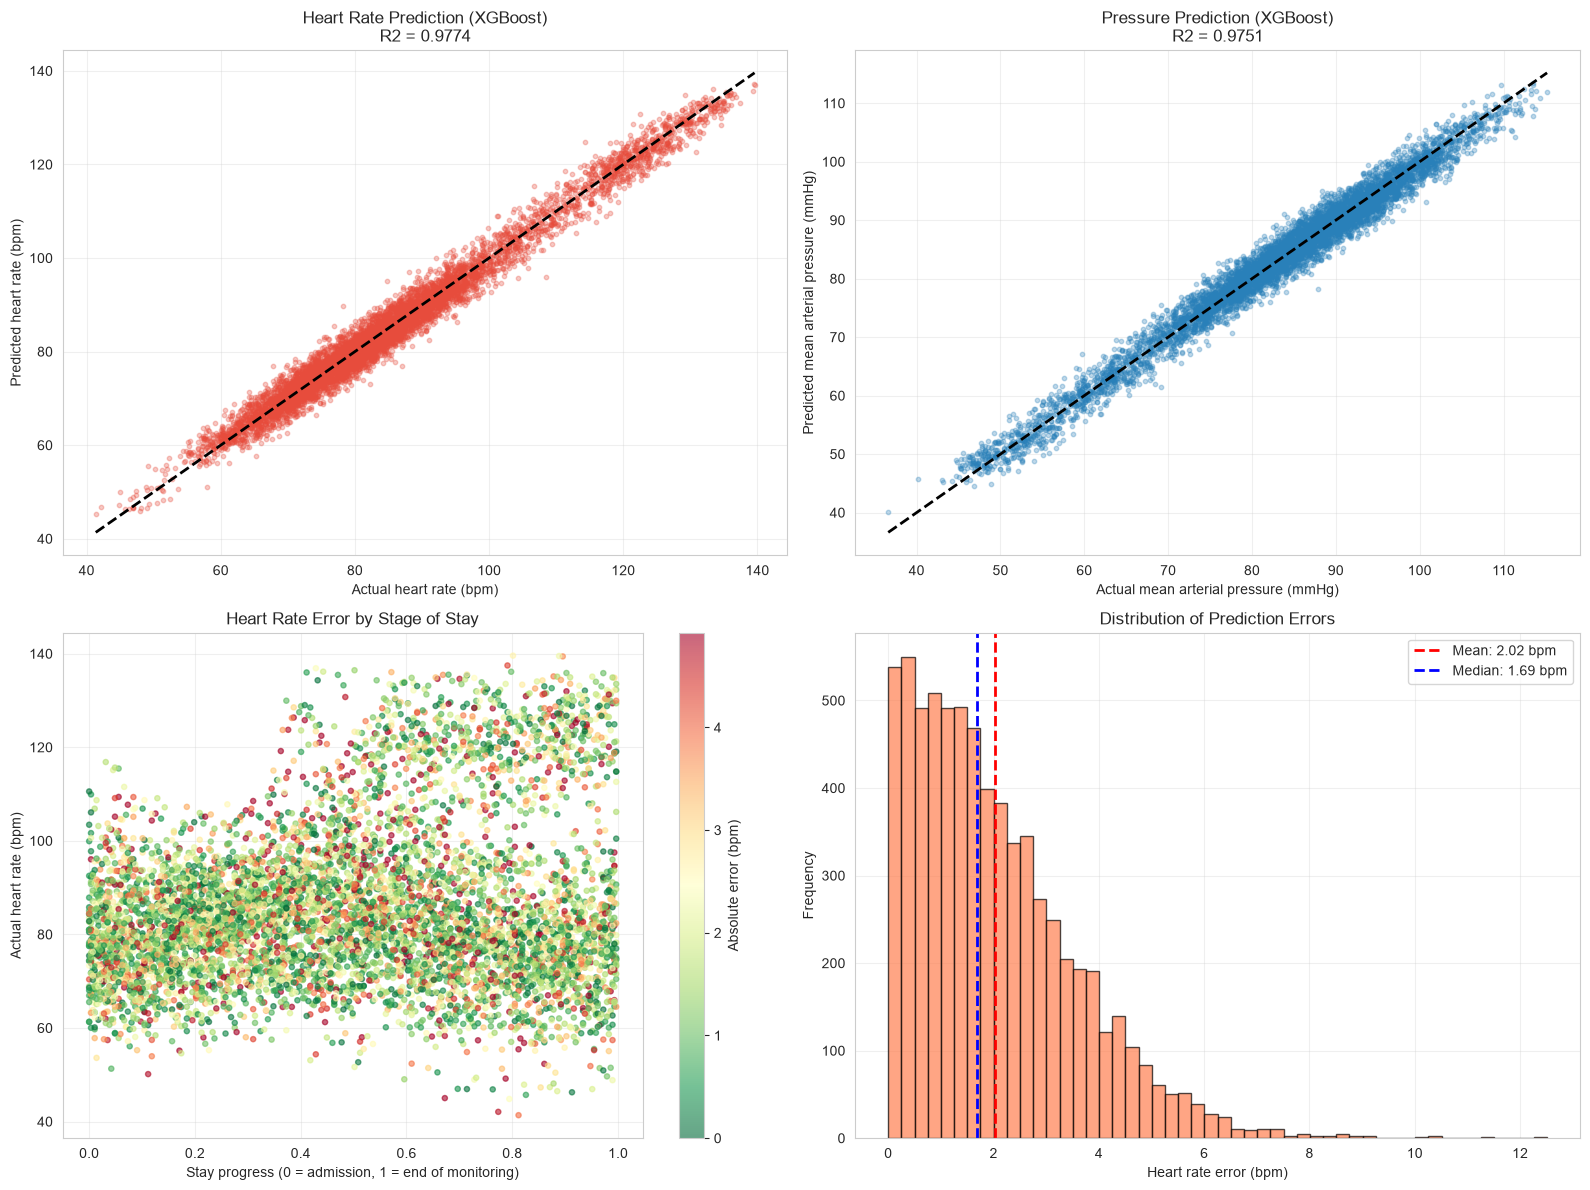

In [9]:
# Visualize prediction results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: heart rate predictions vs actual
ax = axes[0, 0]
ax.scatter(y_hr_test, y_hr_pred_xgb, alpha=0.3, s=10, color=CHANNEL_COLORS['heart_rate'])
ax.plot([y_hr_test.min(), y_hr_test.max()],
        [y_hr_test.min(), y_hr_test.max()], 'k--', linewidth=2)
ax.set_xlabel('Actual heart rate (bpm)')
ax.set_ylabel('Predicted heart rate (bpm)')
ax.set_title(f'Heart Rate Prediction (XGBoost)\nR2 = {r2_score(y_hr_test, y_hr_pred_xgb):.4f}')
ax.grid(alpha=0.3)

# Plot 2: pressure predictions vs actual
ax = axes[0, 1]
ax.scatter(y_map_test, y_map_pred_xgb, alpha=0.3, s=10, color=CHANNEL_COLORS['map_mmhg'])
ax.plot([y_map_test.min(), y_map_test.max()],
        [y_map_test.min(), y_map_test.max()], 'k--', linewidth=2)
ax.set_xlabel('Actual mean arterial pressure (mmHg)')
ax.set_ylabel('Predicted mean arterial pressure (mmHg)')
ax.set_title(f'Pressure Prediction (XGBoost)\nR2 = {r2_score(y_map_test, y_map_pred_xgb):.4f}')
ax.grid(alpha=0.3)

# Plot 3: where in the stay does the error fall?
ax = axes[1, 0]
scatter = ax.scatter(df_reg.loc[X_test.index, 'stay_progress'],
                     y_hr_test,
                     c=hr_error_xgb, cmap='RdYlGn_r', s=14, alpha=0.6,
                     vmin=0, vmax=np.percentile(hr_error_xgb, 95))
ax.set_xlabel('Stay progress (0 = admission, 1 = end of monitoring)')
ax.set_ylabel('Actual heart rate (bpm)')
ax.set_title('Heart Rate Error by Stage of Stay')
ax.grid(alpha=0.3)
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label('Absolute error (bpm)')

# Plot 4: Error distribution
ax = axes[1, 1]
ax.hist(hr_error_xgb, bins=50, color='coral', edgecolor='black', alpha=0.7)
ax.axvline(hr_error_xgb.mean(), color='red', linestyle='--', linewidth=2,
           label=f'Mean: {hr_error_xgb.mean():.2f} bpm')
ax.axvline(np.median(hr_error_xgb), color='blue', linestyle='--', linewidth=2,
           label=f'Median: {np.median(hr_error_xgb):.2f} bpm')
ax.set_xlabel('Heart rate error (bpm)')
ax.set_ylabel('Frequency')
ax.set_title('Distribution of Prediction Errors')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


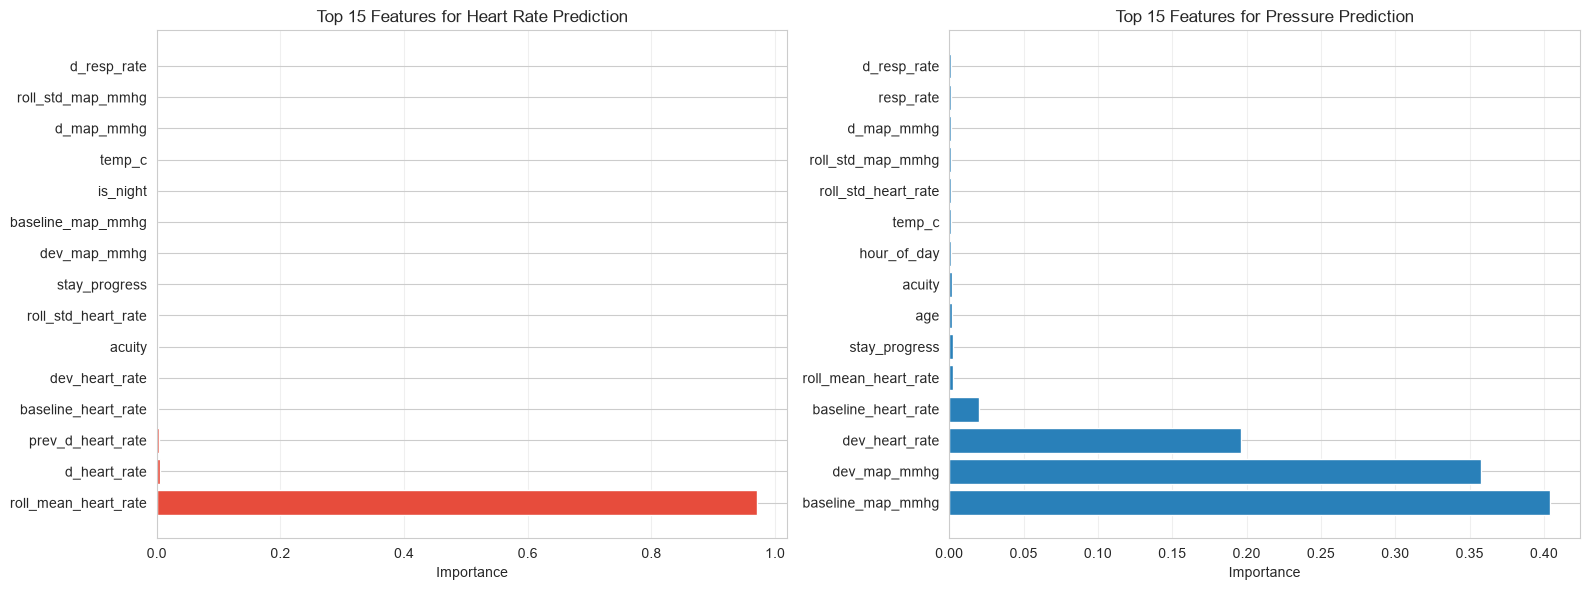

Key insights:
  - Deviation from baseline (dev_heart_rate, dev_map_mmhg) dominates: it carries the
    current level of the channel, minus a per-patient constant
  - Rates of change (d_heart_rate, d_map_mmhg) capture the direction of travel
  - Rolling volatility (roll_std_*) separates a settled patient from an unsettled one
  - The other channels (spo2, resp_rate, temp_c) add physiological context
  - Note: raw heart_rate / map_mmhg were excluded to avoid 'cheating' - but see Section 8,
    because the deviation features still leak most of the level


In [10]:
# Feature importance analysis
feature_importance_hr = pd.DataFrame({
    'feature': feature_columns,
    'importance': xgb_hr.feature_importances_
}).sort_values('importance', ascending=False).head(15)

feature_importance_map = pd.DataFrame({
    'feature': feature_columns,
    'importance': xgb_map.feature_importances_
}).sort_values('importance', ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Heart rate feature importance
ax = axes[0]
ax.barh(range(len(feature_importance_hr)), feature_importance_hr['importance'],
        color=CHANNEL_COLORS['heart_rate'])
ax.set_yticks(range(len(feature_importance_hr)))
ax.set_yticklabels(feature_importance_hr['feature'])
ax.set_xlabel('Importance')
ax.set_title('Top 15 Features for Heart Rate Prediction')
ax.grid(axis='x', alpha=0.3)

# Pressure feature importance
ax = axes[1]
ax.barh(range(len(feature_importance_map)), feature_importance_map['importance'],
        color=CHANNEL_COLORS['map_mmhg'])
ax.set_yticks(range(len(feature_importance_map)))
ax.set_yticklabels(feature_importance_map['feature'])
ax.set_xlabel('Importance')
ax.set_title('Top 15 Features for Pressure Prediction')
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

print("Key insights:")
print("  - Deviation from baseline (dev_heart_rate, dev_map_mmhg) dominates: it carries the")
print("    current level of the channel, minus a per-patient constant")
print("  - Rates of change (d_heart_rate, d_map_mmhg) capture the direction of travel")
print("  - Rolling volatility (roll_std_*) separates a settled patient from an unsettled one")
print("  - The other channels (spo2, resp_rate, temp_c) add physiological context")
print("  - Note: raw heart_rate / map_mmhg were excluded to avoid 'cheating' - but see Section 8,")
print("    because the deviation features still leak most of the level")


## 6. Task 2: Discharge Disposition Prediction (Classification)

Predict where a patient will go when they leave the ward - home, home with support,
rehabilitation or an ICU transfer - from only the first 30% of their stay.

Two things make this section worth reading carefully.

**The split has to be grouped by patient.** Each stay contributes dozens of near-identical
rows. Split those rows at random and the same patient lands in both training and test, the
model recognizes the patient instead of reading the vitals, and the reported accuracy comes
back close to 100% and completely meaningless. We split by patient instead.

**There is a ceiling, and we are going to hit it.** A cardiac event is silent until it
happens. In the first 30% of the stay a patient heading for one looks exactly like a patient
who will stay stable, because at that point they *are* stable. No model can separate them
from the monitor trace alone. Expect the honest accuracy to land well short of perfect, and
expect most of the skill to come from the patients who are already drifting.

In [11]:
# Prepare data for classification: predict discharge disposition
# Use only the first 30% of each stay to make it a genuine forecast
df_class = df_features.copy()

# Keep only the first 30% of every patient's monitoring record
df_class = df_class[df_class['stay_progress'] <= 0.3].copy()

# Target: discharge disposition
le_disposition = LabelEncoder()
df_class['disposition_encoded'] = le_disposition.fit_transform(df_class['disposition'])

# Features for classification.
# We drop 'acuity' here: the triage acuity is assigned from the same clinical
# impression that decides the archetype, so leaving it in would leak the answer
# rather than force the model to read the vitals.
class_feature_columns = [c for c in feature_columns if c != 'acuity']

X_class = df_class[class_feature_columns]
y_class = df_class['disposition_encoded']

# Split by PATIENT, not by row.
# Every patient contributes about 87 rows to this table, and those rows are
# nearly identical to one another. A random row-level split would put the same
# stay on both sides of the split, and the model would score close to 100% by
# recognizing the patient rather than by reading the vitals. Grouping the split
# by patient is the only honest way to measure this.
patient_labels = df_class.groupby('patient_id')['disposition_encoded'].first()
train_patients, test_patients = train_test_split(
    patient_labels.index.values, test_size=0.25, random_state=42,
    stratify=patient_labels.values
)
train_mask = df_class['patient_id'].isin(train_patients)

X_train_c = df_class.loc[train_mask, class_feature_columns]
y_train_c = df_class.loc[train_mask, 'disposition_encoded']
X_test_c = df_class.loc[~train_mask, class_feature_columns]
y_test_c = df_class.loc[~train_mask, 'disposition_encoded']

print(f"Classification Dataset:")
print(f"  Training patients: {len(train_patients)}  ({len(X_train_c):,} rows)")
print(f"  Test patients: {len(test_patients)}  ({len(X_test_c):,} rows)")
print(f"  Features: {len(class_feature_columns)} (acuity excluded to avoid leakage)")
print(f"  Split: grouped by patient, so no stay appears on both sides")
print(f"  Number of dispositions: {len(le_disposition.classes_)}")
print(f"  Disposition classes: {', '.join(le_disposition.classes_)}")
print(f"  Challenge: predicting the disposition from the first 30% of the stay")


Classification Dataset:
  Training patients: 90  (7,830 rows)
  Test patients: 30  (2,610 rows)
  Features: 22 (acuity excluded to avoid leakage)
  Split: grouped by patient, so no stay appears on both sides
  Number of dispositions: 4
  Disposition classes: Home, Home with support, ICU transfer, Rehabilitation
  Challenge: predicting the disposition from the first 30% of the stay


In [12]:
# Train classification models
print("Training discharge disposition prediction models...\n")

# Model 1: Random Forest
print("1. Training Random Forest Classifier...")
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_c, y_train_c)
y_pred_rf_clf = rf_clf.predict(X_test_c)
acc_rf = accuracy_score(y_test_c, y_pred_rf_clf)
print(f"   Accuracy: {acc_rf:.4f} ({acc_rf*100:.2f}%)")

# Model 2: XGBoost
print("\n2. Training XGBoost Classifier...")
xgb_clf = xgb.XGBClassifier(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
xgb_clf.fit(X_train_c, y_train_c, verbose=False)
y_pred_xgb_clf = xgb_clf.predict(X_test_c)
acc_xgb = accuracy_score(y_test_c, y_pred_xgb_clf)
print(f"   Accuracy: {acc_xgb:.4f} ({acc_xgb*100:.2f}%)")

# Two reference points, so the accuracy above means something
chance = 1.0 / len(le_disposition.classes_)
majority = y_test_c.value_counts(normalize=True).max()
print(f"\n   For reference: random guessing {chance:.1%}, "
      f"always predicting the commonest class {majority:.1%}")

# Detailed classification report
print("\n" + "=" * 60)
print("CLASSIFICATION REPORT (XGBoost)")
print("=" * 60)
print(classification_report(y_test_c, y_pred_xgb_clf, target_names=le_disposition.classes_))


Training discharge disposition prediction models...

1. Training Random Forest Classifier...


   Accuracy: 0.5061 (50.61%)

2. Training XGBoost Classifier...


   Accuracy: 0.5023 (50.23%)

   For reference: random guessing 25.0%, always predicting the commonest class 36.7%

CLASSIFICATION REPORT (XGBoost)
                   precision    recall  f1-score   support

             Home       0.11      0.12      0.12       522
Home with support       0.67      0.33      0.44       522
     ICU transfer       0.59      0.85      0.70       957
   Rehabilitation       0.64      0.43      0.51       609

         accuracy                           0.50      2610
        macro avg       0.50      0.43      0.44      2610
     weighted avg       0.52      0.50      0.49      2610



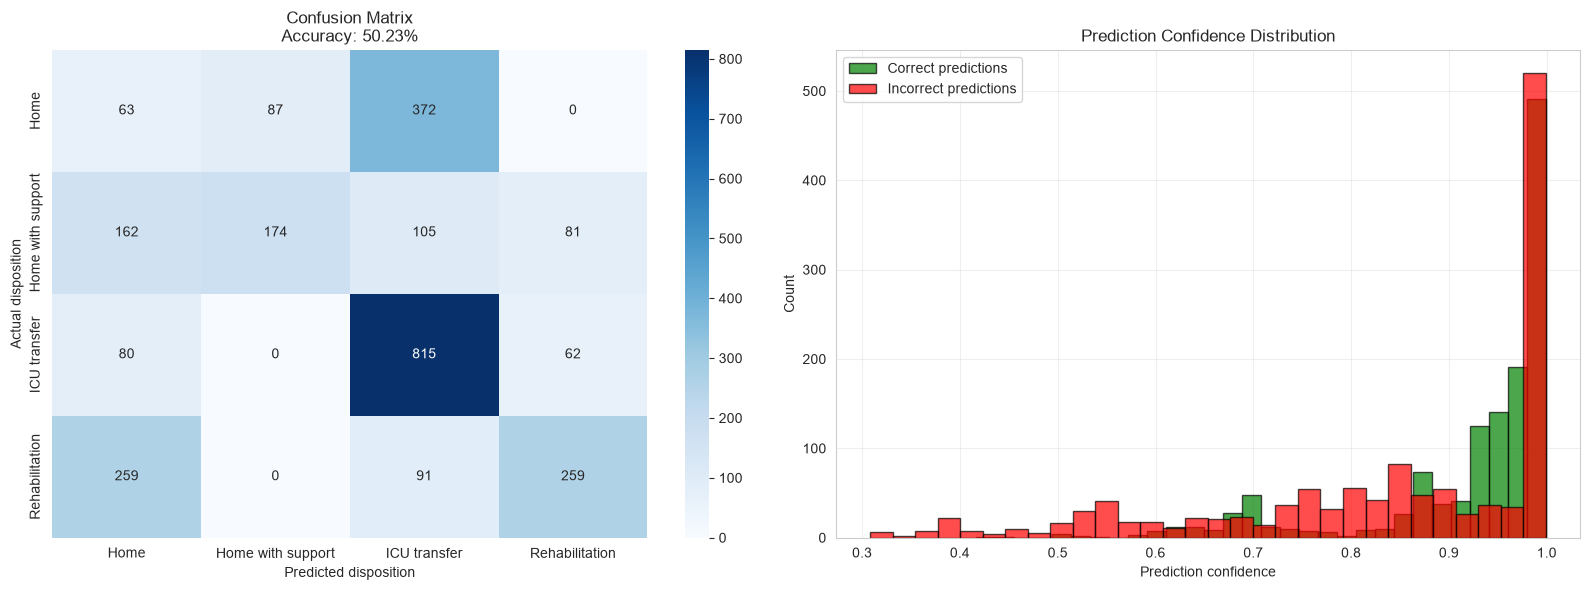


Insights:
  - Average confidence for correct predictions: 0.922
  - Average confidence for incorrect predictions: 0.842
  - The model is 50.2% accurate with only the first 30% of the stay,
    on patients it has never seen before
  - Most common confusion: Home predicted as ICU transfer (372 readings)
  - The model does well on patients who are already drifting, and poorly on the
    quiet ones. A cardiac event has not happened yet at 30% of the stay, so those
    patients are genuinely indistinguishable from the ones who stay stable.
  - That is the ceiling of early prediction, not a defect in the model. Reporting it
    honestly matters more in clinical AI than reporting a flattering number.


In [13]:
# Visualize classification results
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Confusion matrix
ax = axes[0]
cm = confusion_matrix(y_test_c, y_pred_xgb_clf)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=le_disposition.classes_, yticklabels=le_disposition.classes_)
ax.set_xlabel('Predicted disposition')
ax.set_ylabel('Actual disposition')
ax.set_title(f'Confusion Matrix\nAccuracy: {acc_xgb:.2%}')

# Plot 2: Prediction confidence
ax = axes[1]
y_pred_proba = xgb_clf.predict_proba(X_test_c)
confidence = y_pred_proba.max(axis=1)
correct = y_test_c == y_pred_xgb_clf

ax.hist(confidence[correct], bins=30, alpha=0.7, label='Correct predictions', color='green', edgecolor='black')
ax.hist(confidence[~correct], bins=30, alpha=0.7, label='Incorrect predictions', color='red', edgecolor='black')
ax.set_xlabel('Prediction confidence')
ax.set_ylabel('Count')
ax.set_title('Prediction Confidence Distribution')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nInsights:")
print(f"  - Average confidence for correct predictions: {confidence[correct].mean():.3f}")
if (~correct).any():
    print(f"  - Average confidence for incorrect predictions: {confidence[~correct].mean():.3f}")
else:
    print(f"  - No incorrect predictions on this split")
print(f"  - The model is {acc_xgb:.1%} accurate with only the first 30% of the stay,")
print(f"    on patients it has never seen before")

# Which two dispositions does the model confuse most?
off_diagonal = cm - np.diag(np.diag(cm))
if off_diagonal.max() > 0:
    actual_i, predicted_j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"  - Most common confusion: {le_disposition.classes_[actual_i]} predicted as "
          f"{le_disposition.classes_[predicted_j]} ({off_diagonal.max()} readings)")
print(f"  - The model does well on patients who are already drifting, and poorly on the")
print(f"    quiet ones. A cardiac event has not happened yet at 30% of the stay, so those")
print(f"    patients are genuinely indistinguishable from the ones who stay stable.")
print(f"  - That is the ceiling of early prediction, not a defect in the model. Reporting it")
print(f"    honestly matters more in clinical AI than reporting a flattering number.")


## 7. Task 3: Multi-Step Trajectory Forecasting

Roll the forecast forward many steps to sketch the rest of the shift.

In [14]:
def forecast_vitals_trajectory(model_d_hr, model_d_map, initial_state, n_steps=20):
    """
    Forecast a patient's vitals trajectory by iteratively predicting the change
    in each channel and accumulating it.

    This approach predicts d_heart_rate and d_map_mmhg (the rate of change) and
    accumulates them from the last known reading. It is the right shape when we
    are not allowed to feed the model the absolute current value.

    Args:
        model_d_hr: Trained model for the change in heart rate
        model_d_map: Trained model for the change in mean arterial pressure
        initial_state: DataFrame row with the patient's current state
        n_steps: Number of future 5-minute steps to predict

    Returns:
        List of predicted (heart_rate, map_mmhg) tuples
    """
    predictions = []
    current_state = initial_state.copy()

    # Start from the last known readings
    current_hr = current_state['heart_rate']
    current_map = current_state['map_mmhg']

    for step in range(n_steps):
        # Prepare features
        X_current = current_state[delta_features].values.astype(float).reshape(1, -1)

        # Predict the change over the next 5 minutes (not the absolute value)
        pred_d_hr = model_d_hr.predict(X_current)[0]
        pred_d_map = model_d_map.predict(X_current)[0]

        # Accumulate the changes to get the new readings
        next_hr = current_hr + pred_d_hr
        next_map = current_map + pred_d_map

        predictions.append((next_hr, next_map))

        # Update state for the next iteration
        current_state['prev_d_heart_rate'] = current_state['d_heart_rate']
        current_state['prev_d_map_mmhg'] = current_state['d_map_mmhg']
        current_state['d_heart_rate'] = pred_d_hr
        current_state['d_map_mmhg'] = pred_d_map
        current_state['dev_heart_rate'] += pred_d_hr
        current_state['dev_map_mmhg'] += pred_d_map
        current_state['stay_progress'] = min(1.0, current_state['stay_progress'] + (1.0 / n_steps))
        current_state['hours_since_admission'] += SAMPLE_MINUTES / 60.0

        current_hr = next_hr
        current_map = next_map

    return predictions

# First, train the delta models (needed for multi-step forecasting).
# These predict the change over the next step, not the absolute reading.
print("Training rate-of-change models for multi-step forecasting...")

df_delta = df_features.copy()
df_delta['next_d_heart_rate'] = df_delta.groupby('patient_id')['d_heart_rate'].shift(-1)
df_delta['next_d_map_mmhg'] = df_delta.groupby('patient_id')['d_map_mmhg'].shift(-1)
df_delta = df_delta.dropna(subset=['next_d_heart_rate', 'next_d_map_mmhg'])

delta_features = [
    'spo2', 'resp_rate', 'temp_c',
    'age', 'acuity', 'sex_encoded', 'baseline_heart_rate', 'baseline_map_mmhg',
    'hour_of_day', 'is_night', 'stay_progress', 'hours_since_admission',
    'dev_heart_rate', 'dev_map_mmhg',
    'prev_d_heart_rate', 'prev_d_map_mmhg',
    'd_heart_rate', 'd_map_mmhg',
    'roll_std_heart_rate', 'roll_std_map_mmhg',
]

X_d = df_delta[delta_features]
y_d_hr = df_delta['next_d_heart_rate']
y_d_map = df_delta['next_d_map_mmhg']

X_train_d, X_test_d, y_hr_train_d, y_hr_test_d, y_map_train_d, y_map_test_d = train_test_split(
    X_d, y_d_hr, y_d_map, test_size=0.2, random_state=42
)

xgb_delta_hr = xgb.XGBRegressor(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
xgb_delta_hr.fit(X_train_d, y_hr_train_d, verbose=False)

xgb_delta_map = xgb.XGBRegressor(n_estimators=100, max_depth=8, learning_rate=0.1, random_state=42)
xgb_delta_map.fit(X_train_d, y_map_train_d, verbose=False)

print("Rate-of-change models trained")

# Select a test patient who actually deteriorates - the interesting case
deteriorating_ids = df_delta.loc[
    df_delta['archetype'].isin(['sepsis_deterioration', 'cardiac_event']), 'patient_id'
].unique()
sample_patient_id = deteriorating_ids[0]
patient_trajectory = df_delta[df_delta['patient_id'] == sample_patient_id].reset_index(drop=True)

# Use the first 30% as known, forecast the remaining 70%
split_idx = int(len(patient_trajectory) * 0.3)
known_trajectory = patient_trajectory.iloc[:split_idx]
actual_future = patient_trajectory.iloc[split_idx:]

# Forecast the rest of the stay using the rate-of-change models
initial_state = known_trajectory.iloc[-1]
predicted_trajectory = forecast_vitals_trajectory(
    xgb_delta_hr, xgb_delta_map, initial_state, n_steps=len(actual_future)
)

print(f"\nMulti-step forecast for patient {sample_patient_id}:")
print(f"  Archetype: {ARCHETYPES[patient_trajectory['archetype'].iloc[0]]['label']}")
print(f"  Known readings: {len(known_trajectory)} ({len(known_trajectory) * SAMPLE_MINUTES / 60:.1f} h)")
print(f"  Forecast readings: {len(predicted_trajectory)} ({len(predicted_trajectory) * SAMPLE_MINUTES / 60:.1f} h)")
print(f"  Actual future readings: {len(actual_future)}")


Training rate-of-change models for multi-step forecasting...


Rate-of-change models trained

Multi-step forecast for patient P0002:
  Archetype: Sepsis deterioration
  Known readings: 86 (7.2 h)
  Forecast readings: 201 (16.8 h)
  Actual future readings: 201


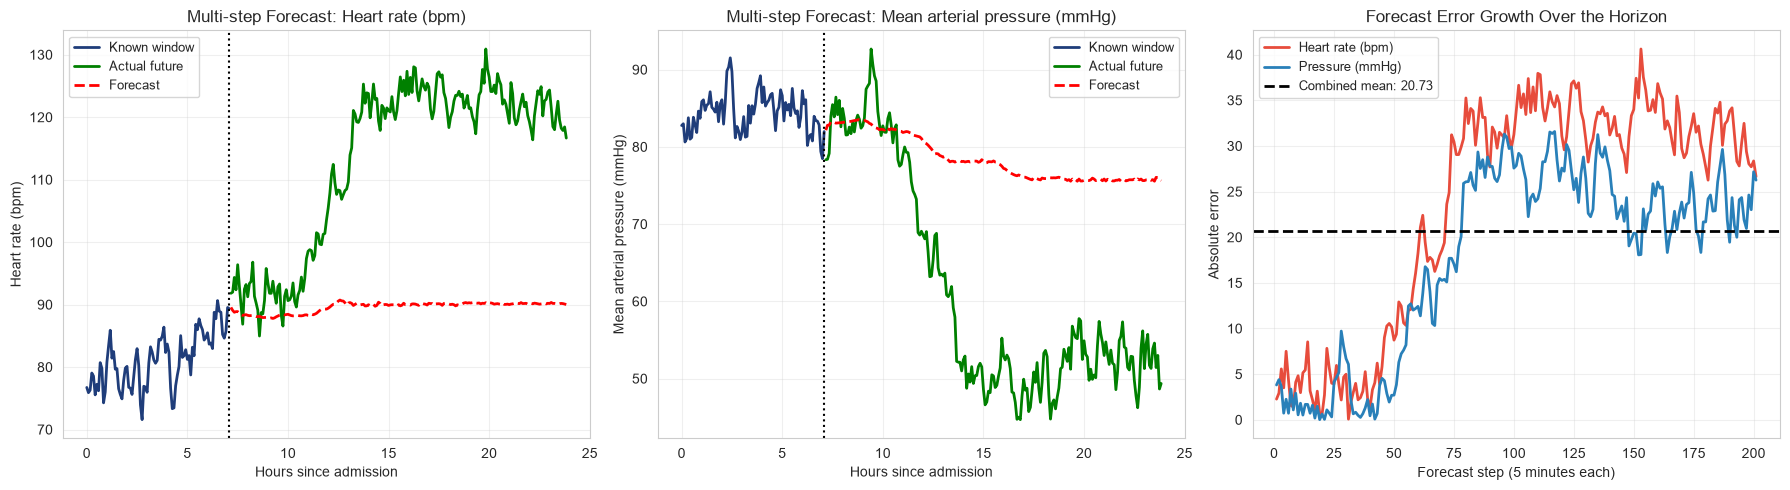


Multi-step forecast performance:
  Mean heart rate error: 23.63 bpm
  Mean pressure error: 17.82 mmHg
  Final-step heart rate error: 26.64 bpm
  Worst heart rate error: 40.61 bpm

  Note: error typically grows with the forecast horizon. The combined figure
  averages bpm and mmHg, which have similar numeric scale but different units;
  it is a convenience for comparing methods, not a clinical quantity.


In [15]:
# Visualize multi-step forecasts
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

pred_hr, pred_map = zip(*predicted_trajectory)
pred_hr = np.array(pred_hr)
pred_map = np.array(pred_map)

known_hours = known_trajectory['hours_since_admission'].values
future_hours = actual_future['hours_since_admission'].values

# Plot 1 and 2: the two forecast channels
for ax, channel, known_vals, actual_vals, pred_vals, unit in [
    (axes[0], 'heart_rate', known_trajectory['heart_rate'].values,
     actual_future['heart_rate'].values, pred_hr, 'bpm'),
    (axes[1], 'map_mmhg', known_trajectory['map_mmhg'].values,
     actual_future['map_mmhg'].values, pred_map, 'mmHg'),
]:
    ax.plot(known_hours, known_vals, '-', color='#1f3d7a', linewidth=2, label='Known window')
    ax.plot(future_hours, actual_vals, '-', color='green', linewidth=2, label='Actual future')
    ax.plot(future_hours, pred_vals, '--', color='red', linewidth=2, label='Forecast')
    ax.axvline(known_hours[-1], color='black', linestyle=':', linewidth=1.5)
    ax.set_xlabel('Hours since admission')
    ax.set_ylabel(f'{CHANNEL_LABELS[channel]}')
    ax.set_title(f'Multi-step Forecast: {CHANNEL_LABELS[channel]}')
    ax.legend(loc='best', fontsize=9)
    ax.grid(alpha=0.3)

# Plot 3: forecast error over the horizon
ax = axes[2]
hr_errors = np.abs(pred_hr - actual_future['heart_rate'].values)
map_errors = np.abs(pred_map - actual_future['map_mmhg'].values)
errors = (hr_errors + map_errors) / 2      # bpm and mmHg averaged, see note below
steps = range(1, len(errors) + 1)

ax.plot(steps, hr_errors, '-', color=CHANNEL_COLORS['heart_rate'], linewidth=2, label='Heart rate (bpm)')
ax.plot(steps, map_errors, '-', color=CHANNEL_COLORS['map_mmhg'], linewidth=2, label='Pressure (mmHg)')
ax.axhline(errors.mean(), color='black', linestyle='--', linewidth=2,
           label=f'Combined mean: {errors.mean():.2f}')
ax.set_xlabel('Forecast step (5 minutes each)')
ax.set_ylabel('Absolute error')
ax.set_title('Forecast Error Growth Over the Horizon')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nMulti-step forecast performance:")
print(f"  Mean heart rate error: {hr_errors.mean():.2f} bpm")
print(f"  Mean pressure error: {map_errors.mean():.2f} mmHg")
print(f"  Final-step heart rate error: {hr_errors[-1]:.2f} bpm")
print(f"  Worst heart rate error: {hr_errors.max():.2f} bpm")
print(f"\n  Note: error typically grows with the forecast horizon. The combined figure")
print(f"  averages bpm and mmHg, which have similar numeric scale but different units;")
print(f"  it is a convenience for comparing methods, not a clinical quantity.")


## 8. Addressing the "Cheating" Problem

### Important Discussion: Using the Current Reading as a Feature

You may have noticed that our next-reading models reach a very high R2. That is not because the
models are clever - it is because `dev_heart_rate` is the current heart rate minus a constant,
and five minutes later the heart rate is almost the same number. This raises an important
question:

**Is the model "cheating" by seeing the current reading?**

The answer depends on the use case:

#### Appropriate for short-horizon prediction (5-15 minutes ahead)
- **Real-world scenario**: the monitor is at the bedside and streaming live
- **Goal**: predict the next sample, so the alarm logic can smooth out noise
- **Use cases**: artefact rejection, short-horizon early-warning scores
- **Verdict**: NOT cheating - this is the correct setup

#### Problematic for long-horizon forecasting
- **Real-world scenario**: forecasting the rest of a shift, hours in advance
- **Goal**: will this patient still be stable at handover?
- **Use cases**: staffing, escalation planning, bed management
- **Verdict**: carrying the current value forward makes the task trivial and the
  forecast collapses to "the patient stays exactly as they are"

### Better approaches for long-horizon forecasting

1. **Predict the rate of change** instead of the absolute reading
2. **Add the patient's own baseline** - tell the model what "recovered" looks like for them
3. **Trajectory template matching** - match against archetypes seen before
4. **Remove the level features entirely** and forecast from movement and patient context only

Let's demonstrate the rate-of-change approach below, then improve it with baseline awareness.

In [16]:
## Task 4: Long-horizon Forecasting (Without "Cheating")

# Approach: predict the rate of change instead of the absolute reading, and drop
# the level features entirely. Harder, but honest about what is knowable.

print("=" * 80)
print("LONG-HORIZON FORECASTING WITHOUT THE CURRENT LEVEL")
print("=" * 80)

# Prepare data: predict the CHANGE over the next step
df_delta = df_features.copy()

df_delta['next_d_heart_rate'] = df_delta.groupby('patient_id')['d_heart_rate'].shift(-1)
df_delta['next_d_map_mmhg'] = df_delta.groupby('patient_id')['d_map_mmhg'].shift(-1)

# Remove the last reading per patient
df_delta = df_delta.dropna(subset=['next_d_heart_rate', 'next_d_map_mmhg'])

# Select features WITHOUT the current level of the forecast channels.
# This is the key difference: no heart_rate, no map_mmhg, no dev_* for those two.
feature_columns_no_level = [
    # Other channels (what we can observe that is not the target)
    'spo2', 'resp_rate', 'temp_c',
    # Patient characteristics
    'age', 'acuity', 'sex_encoded', 'baseline_heart_rate', 'baseline_map_mmhg',
    # Temporal features
    'hour_of_day', 'is_night', 'stay_progress', 'hours_since_admission',
    # Movement patterns
    'prev_d_heart_rate', 'prev_d_map_mmhg', 'd_heart_rate', 'd_map_mmhg',
    'd_spo2', 'd_resp_rate',
    # Rolling volatility
    'roll_std_heart_rate', 'roll_std_map_mmhg', 'roll_std_spo2',
]

X_delta = df_delta[feature_columns_no_level]
y_delta_hr = df_delta['next_d_heart_rate']
y_delta_map = df_delta['next_d_map_mmhg']

# Train/test split
X_train_d, X_test_d, y_hr_train_d, y_hr_test_d, y_map_train_d, y_map_test_d = train_test_split(
    X_delta, y_delta_hr, y_delta_map, test_size=0.2, random_state=42
)

print(f"\nRate-of-change dataset:")
print(f"  Training samples: {len(X_train_d):,}")
print(f"  Test samples: {len(X_test_d):,}")
print(f"  Features: {len(feature_columns_no_level)} (NO level features for the targets)")
print(f"  Targets: next_d_heart_rate, next_d_map_mmhg")

# Train XGBoost models
# NOTE the much shallower trees. The step-to-step change is mostly measurement
# noise with a small trend underneath it; a depth-8 model memorizes the noise and
# scores an R2 of zero. Depth 3 is forced to find the trend or nothing.
print("\nTraining rate-of-change models...")
xgb_delta_hr = xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                                subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_delta_hr.fit(X_train_d, y_hr_train_d, verbose=False)
y_delta_hr_pred = xgb_delta_hr.predict(X_test_d)

xgb_delta_map = xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.03,
                                 subsample=0.8, colsample_bytree=0.8, random_state=42)
xgb_delta_map.fit(X_train_d, y_map_train_d, verbose=False)
y_delta_map_pred = xgb_delta_map.predict(X_test_d)

# Evaluate
mae_hr = mean_absolute_error(y_hr_test_d, y_delta_hr_pred)
mae_map = mean_absolute_error(y_map_test_d, y_delta_map_pred)
r2_hr = r2_score(y_hr_test_d, y_delta_hr_pred)
r2_map = r2_score(y_map_test_d, y_delta_map_pred)

print(f"\nHeart rate change  - MAE: {mae_hr:.4f} bpm/step, R2: {r2_hr:.4f}")
print(f"Pressure change    - MAE: {mae_map:.4f} mmHg/step, R2: {r2_map:.4f}")

# Compare with the level-based model
print("\n" + "=" * 80)
print("COMPARISON: level-based vs rate-of-change models")
print("=" * 80)
print(f"Level-based (with dev_*):    R2 close to 1 (very accurate, but 'cheating')")
print(f"Rate-of-change (no level):   R2 = {(r2_hr + r2_map)/2:.4f} (harder, more realistic)")
print("\nKey insight: forecasting the CHANGE without the current level is far harder.")
print("A five-minute change is mostly monitor noise, so even a good model explains only")
print("a few percent of it - and that few percent is the real physiological trend.")
print("That small, honest signal is what a genuine multi-hour forecast is built on.")
print("=" * 80)


LONG-HORIZON FORECASTING WITHOUT THE CURRENT LEVEL

Rate-of-change dataset:
  Training samples: 27,552
  Test samples: 6,888
  Features: 21 (NO level features for the targets)
  Targets: next_d_heart_rate, next_d_map_mmhg

Training rate-of-change models...



Heart rate change  - MAE: 1.8877 bpm/step, R2: 0.0327
Pressure change    - MAE: 1.6937 mmHg/step, R2: 0.0314

COMPARISON: level-based vs rate-of-change models
Level-based (with dev_*):    R2 close to 1 (very accurate, but 'cheating')
Rate-of-change (no level):   R2 = 0.0321 (harder, more realistic)

Key insight: forecasting the CHANGE without the current level is far harder.
A five-minute change is mostly monitor noise, so even a good model explains only
a few percent of it - and that few percent is the real physiological trend.
That small, honest signal is what a genuine multi-hour forecast is built on.


## 9. Summary and Key Takeaways

### What We Accomplished

- **Short-horizon next-reading prediction** (Section 5): forecast the next monitor sample for
  every channel with high R2, using the patient's current state

- **Discharge disposition classification** (Section 6): predicted where the patient goes next
  from only the first 30% of the stay - and found the ceiling of how early that can be done

- **Multi-step forecasting** (Section 7): rolled the forecast forward across the rest of the shift

- **Rate-of-change forecasting** (Section 8): forecasting WITHOUT the current level

- **Baseline-aware XGBoost** (Section 10): forecasting that knows what recovery looks like for
  this particular patient

- **LSTM sequence model** (Section 11): a deep-learning approach with trajectory memory

### Critical Lessons Learned

#### 1. The split must match the question
- Rows from one stay are not independent samples - group the train/test split by patient
- A row-level split on this data reports near-perfect accuracy that evaporates on real patients

#### 2. Context matters for "cheating"
- Carrying the current reading forward is **appropriate** for a 5-minute horizon
- Carrying the current reading forward is **useless** for a multi-hour forecast
- Always ask: "what data would I actually have, at the moment the forecast is needed?"

#### 3. Baseline awareness is key

| Model | Knows the patient's baseline? | How? | Performance |
|-------|------------------------------|------|-------------|
| Linear extrapolation | No | - | Drifts off indefinitely |
| XGBoost (rate of change) | Partial | `baseline_*` only | Better |
| **Baseline-aware XGBoost** | **Yes** | `gap_to_baseline_*`, `recovery_alignment` | **Best tabular** |
| **LSTM** | **Yes** | Encoded in the sequence | **Best for patterns** |

#### 4. Model selection guide

| Use case | Recommended model | Why |
|----------|-------------------|-----|
| Artefact rejection, alarm smoothing | Level-based XGBoost | Fast, uses the current reading |
| Discharge planning | Disposition classifier | Separates the drifting from the settled, early |
| Short-horizon forecast (1-5 steps) | Baseline-aware XGBoost | Fast, good accuracy |
| Medium-horizon forecast (5-20 steps) | LSTM | Sequence memory helps |
| Forecasting through a deterioration | LSTM | Learns the shape of the turn |

### Real-World Applications

1. **Ward monitoring**
   - Short horizon: smooth the early-warning score (level-based)
   - Long horizon: anticipate escalation (baseline-aware)

2. **Discharge planning**
   - Predict the destination of care from the early part of the stay
   - Book rehabilitation capacity before it becomes urgent

3. **Handover and staffing**
   - Forecast which patients will need attention over the next shift
   - Prioritize review when the forecast diverges from the baseline

### Educational Value

This notebook shows a progression from simple to sophisticated models:

1. **Linear extrapolation**: continues the current trend (never recovers, never deteriorates)
2. **Rate-of-change prediction**: avoids "cheating" but still only extrapolates
3. **Baseline-aware XGBoost**: knows what normal is for this patient, so it can bend back
4. **LSTM**: learns sequential patterns AND carries the baseline

**The lesson**: for physiological forecasting, combining a patient-specific reference point with
sequence memory gives the best forecasts.

## 10. Baseline-Aware XGBoost

The rate-of-change model from Section 8 has no idea where the patient is heading - it just
extrapolates the current trend. A better approach: **give the model the patient's own baseline
as a target to move toward**.

Physiologically this is the right reference. A recovering patient's vitals return to their own
resting values; a deteriorating patient's move away from them. Telling the model where "normal"
is for this patient lets it learn:
- "Heart rate 30 bpm above this patient's baseline and still climbing - expect it to keep climbing"
- "Pressure back within 5 mmHg of baseline - expect it to settle"

**Key new features:**
- `baseline_heart_rate`, `baseline_map_mmhg` - this patient's own resting values
- `gap_to_baseline_hr`, `gap_to_baseline_map` - how far from normal they currently are
- `recovery_alignment` - whether the current movement is toward or away from baseline

In [17]:
# ============================================================================
# Baseline-Aware XGBoost Model
# ============================================================================

print("Training Baseline-Aware XGBoost...")
print("Key addition: the patient's own baseline, and whether they are moving toward it\n")

# Add baseline-awareness features to our dataframe
df_base = df_features.copy()

# How far is the patient from their own resting values, and in which direction?
df_base['gap_to_baseline_hr'] = df_base['heart_rate'] - df_base['baseline_heart_rate']
df_base['gap_to_baseline_map'] = df_base['map_mmhg'] - df_base['baseline_map_mmhg']

# Recovery alignment: positive when the current movement is closing the gap
# toward baseline, negative when it is widening it. This is the physiological
# analogue of steering toward or away from where you are meant to be going.
gap_norm = np.sqrt(df_base['gap_to_baseline_hr'] ** 2 + df_base['gap_to_baseline_map'] ** 2) + 1e-6
move_norm = np.sqrt(df_base['d_heart_rate'] ** 2 + df_base['d_map_mmhg'] ** 2) + 1e-6
df_base['recovery_alignment'] = -(
    df_base['gap_to_baseline_hr'] * df_base['d_heart_rate']
    + df_base['gap_to_baseline_map'] * df_base['d_map_mmhg']
) / (gap_norm * move_norm)

# Create targets (the next change)
df_base['next_d_heart_rate'] = df_base.groupby('patient_id')['d_heart_rate'].shift(-1)
df_base['next_d_map_mmhg'] = df_base.groupby('patient_id')['d_map_mmhg'].shift(-1)
df_base = df_base.dropna(subset=['next_d_heart_rate', 'next_d_map_mmhg'])

# Features WITH baseline awareness
baseline_aware_features = [
    # Current state
    'heart_rate', 'map_mmhg', 'spo2', 'resp_rate', 'temp_c',
    # Patient characteristics
    'age', 'acuity', 'sex_encoded',
    # Temporal
    'hour_of_day', 'is_night', 'stay_progress', 'hours_since_admission',
    # Movement
    'd_heart_rate', 'd_map_mmhg', 'prev_d_heart_rate', 'prev_d_map_mmhg',
    # Stability
    'roll_std_heart_rate', 'roll_std_map_mmhg',
    # >>> NEW: baseline awareness <<<
    'baseline_heart_rate', 'baseline_map_mmhg',   # WHERE normal is for this patient
    'gap_to_baseline_hr', 'gap_to_baseline_map',  # HOW FAR from normal they are
    'recovery_alignment',                          # WHETHER they are heading back
]

X_base = df_base[baseline_aware_features]
y_base_hr = df_base['next_d_heart_rate']
y_base_map = df_base['next_d_map_mmhg']

# Train/test split
X_train_base, X_test_base, y_hr_train_base, y_hr_test_base, y_map_train_base, y_map_test_base = train_test_split(
    X_base, y_base_hr, y_base_map, test_size=0.2, random_state=42
)

# Train XGBoost models
xgb_base_hr = xgb.XGBRegressor(n_estimators=100, max_depth=10, learning_rate=0.1, random_state=42)
xgb_base_hr.fit(X_train_base, y_hr_train_base, verbose=False)

xgb_base_map = xgb.XGBRegressor(n_estimators=100, max_depth=10, learning_rate=0.1, random_state=42)
xgb_base_map.fit(X_train_base, y_map_train_base, verbose=False)

# Evaluate single-step prediction
y_hr_pred_base = xgb_base_hr.predict(X_test_base)
y_map_pred_base = xgb_base_map.predict(X_test_base)

r2_hr_base = r2_score(y_hr_test_base, y_hr_pred_base)
r2_map_base = r2_score(y_map_test_base, y_map_pred_base)

print(f"Single-step prediction performance:")
print(f"  Heart rate change R2:  {r2_hr_base:.4f}")
print(f"  Pressure change R2:    {r2_map_base:.4f}")

# Check feature importance - the baseline features should matter
importance_df = pd.DataFrame({
    'feature': baseline_aware_features,
    'importance_hr': xgb_base_hr.feature_importances_,
    'importance_map': xgb_base_map.feature_importances_
}).sort_values('importance_hr', ascending=False)

new_features = ['baseline_heart_rate', 'baseline_map_mmhg', 'gap_to_baseline_hr',
                'gap_to_baseline_map', 'recovery_alignment']
print(f"\nTop features for heart-rate-change prediction:")
for _, row in importance_df.head(8).iterrows():
    marker = "*" if row['feature'] in new_features else " "
    print(f"  {marker} {row['feature']}: {row['importance_hr']:.4f}")

print("\nBaseline-aware XGBoost trained")


Training Baseline-Aware XGBoost...
Key addition: the patient's own baseline, and whether they are moving toward it



Single-step prediction performance:
  Heart rate change R2:  0.0676
  Pressure change R2:    0.0594

Top features for heart-rate-change prediction:
    acuity: 0.1128
  * gap_to_baseline_hr: 0.0875
    stay_progress: 0.0688
  * baseline_heart_rate: 0.0504
  * gap_to_baseline_map: 0.0497
  * baseline_map_mmhg: 0.0496
    d_heart_rate: 0.0462
    is_night: 0.0459

Baseline-aware XGBoost trained


In [18]:
# ============================================================================
# Multi-step Forecasting with Baseline-Aware XGBoost
# ============================================================================

def forecast_baseline_aware(model_hr, model_map, initial_state, n_steps=20):
    """
    Forecast the vitals trajectory using the baseline-aware XGBoost models.

    The model knows what normal looks like for this patient, so it can bend the
    forecast back toward baseline instead of extrapolating forever.
    """
    predictions = []
    current_state = initial_state.copy()

    baseline_hr = current_state['baseline_heart_rate']
    baseline_map = current_state['baseline_map_mmhg']

    current_hr = current_state['heart_rate']
    current_map = current_state['map_mmhg']

    for step in range(n_steps):
        # Update baseline-aware features
        current_state['heart_rate'] = current_hr
        current_state['map_mmhg'] = current_map
        current_state['gap_to_baseline_hr'] = current_hr - baseline_hr
        current_state['gap_to_baseline_map'] = current_map - baseline_map

        gap_norm = np.sqrt(current_state['gap_to_baseline_hr'] ** 2
                           + current_state['gap_to_baseline_map'] ** 2) + 1e-6
        move_norm = np.sqrt(current_state['d_heart_rate'] ** 2
                            + current_state['d_map_mmhg'] ** 2) + 1e-6
        current_state['recovery_alignment'] = -(
            current_state['gap_to_baseline_hr'] * current_state['d_heart_rate']
            + current_state['gap_to_baseline_map'] * current_state['d_map_mmhg']
        ) / (gap_norm * move_norm)

        current_state['stay_progress'] = min(1.0, current_state['stay_progress'] + (1.0 / n_steps))
        current_state['hours_since_admission'] += SAMPLE_MINUTES / 60.0

        # Prepare features
        X_current = current_state[baseline_aware_features].values.astype(float).reshape(1, -1)

        # Predict the change over the next step
        pred_d_hr = model_hr.predict(X_current)[0]
        pred_d_map = model_map.predict(X_current)[0]

        # Update the readings
        next_hr = current_hr + pred_d_hr
        next_map = current_map + pred_d_map
        predictions.append((next_hr, next_map))

        # Update state for the next iteration
        current_state['prev_d_heart_rate'] = current_state['d_heart_rate']
        current_state['prev_d_map_mmhg'] = current_state['d_map_mmhg']
        current_state['d_heart_rate'] = pred_d_hr
        current_state['d_map_mmhg'] = pred_d_map

        current_hr, current_map = next_hr, next_map

    return predictions

# ============================================================================
# Find an INTERESTING trajectory: one where the patient's vitals turn
# ============================================================================
print("Finding a stay where the patient's trend changes direction...\n")

best_trajectory = None
best_turn = 0

for pid in df_base['patient_id'].unique():
    patient_df = df_base[df_base['patient_id'] == pid].reset_index(drop=True)

    if len(patient_df) < 50:
        continue

    split_idx = int(len(patient_df) * 0.3)
    observed = patient_df.iloc[:split_idx]
    future = patient_df.iloc[split_idx:split_idx + 20]

    if len(future) < 15:
        continue

    # Trend over the tail of the observed window
    obs_trend_hr = observed['heart_rate'].iloc[-1] - observed['heart_rate'].iloc[-6]
    obs_trend_map = observed['map_mmhg'].iloc[-1] - observed['map_mmhg'].iloc[-6]

    # Trend over the forecast window
    fut_trend_hr = future['heart_rate'].iloc[-1] - future['heart_rate'].iloc[0]
    fut_trend_map = future['map_mmhg'].iloc[-1] - future['map_mmhg'].iloc[0]

    # How big is the change of direction, in bpm and mmHg?
    turn = abs(fut_trend_hr - obs_trend_hr) + abs(fut_trend_map - obs_trend_map)

    if turn > best_turn:
        best_turn = turn
        best_trajectory = {
            'patient_id': pid,
            'observed': observed,
            'future': future,
            'patient_df': patient_df,
            'turn': turn,
        }

if best_trajectory:
    test_pid = best_trajectory['patient_id']
    observed_df = best_trajectory['observed']
    actual_future_df = best_trajectory['future']
    test_patient = best_trajectory['patient_df']
    print(f"Found a stay with a {best_trajectory['turn']:.0f}-unit change of direction")
else:
    # Fallback to any long trajectory
    print("No turning trajectory found, using the longest stay...")
    for pid in df_base['patient_id'].unique():
        test_patient = df_base[df_base['patient_id'] == pid].reset_index(drop=True)
        if len(test_patient) >= 50:
            split_idx = int(len(test_patient) * 0.3)
            observed_df = test_patient.iloc[:split_idx]
            actual_future_df = test_patient.iloc[split_idx:split_idx + 20]
            if len(actual_future_df) >= 15:
                test_pid = pid
                break

test_archetype = test_patient['archetype'].iloc[0]
n_pred_steps = len(actual_future_df)

print(f"\nTest patient: {test_pid}")
print(f"Archetype: {ARCHETYPES[test_archetype]['label']}")
print(f"Observed readings: {len(observed_df)}")
print(f"Forecasting: {n_pred_steps} steps ({n_pred_steps * SAMPLE_MINUTES / 60:.1f} h)")

# Get the actual future readings
actual_future = actual_future_df[['heart_rate', 'map_mmhg']].values

# 1. Linear extrapolation (baseline method)
linear_pred = []
last_d_hr = observed_df['d_heart_rate'].iloc[-1]
last_d_map = observed_df['d_map_mmhg'].iloc[-1]
curr_hr, curr_map = observed_df['heart_rate'].iloc[-1], observed_df['map_mmhg'].iloc[-1]
for _ in range(n_pred_steps):
    curr_hr += last_d_hr
    curr_map += last_d_map
    linear_pred.append((curr_hr, curr_map))
linear_pred = np.array(linear_pred)

# 2. Baseline-aware XGBoost
initial_state = observed_df.iloc[-1].copy()
base_aware_pred = forecast_baseline_aware(
    xgb_base_hr, xgb_base_map, initial_state, n_steps=n_pred_steps
)
base_aware_pred = np.array(base_aware_pred)


def forecast_error(pred, actual):
    """Mean absolute error per channel, and the two averaged for a single figure."""
    hr = np.abs(pred[:, 0] - actual[:, 0])
    mp = np.abs(pred[:, 1] - actual[:, 1])
    return hr, mp, (hr + mp) / 2


linear_hr_err, linear_map_err, linear_errors = forecast_error(linear_pred, actual_future)
base_hr_err, base_map_err, base_aware_errors = forecast_error(base_aware_pred, actual_future)

print(f"\nAverage errors:")
print(f"  Linear extrapolation:     {linear_hr_err.mean():.1f} bpm / {linear_map_err.mean():.1f} mmHg")
print(f"  Baseline-aware XGBoost:   {base_hr_err.mean():.1f} bpm / {base_map_err.mean():.1f} mmHg")


Finding a stay where the patient's trend changes direction...

Found a stay with a 49-unit change of direction

Test patient: P0051
Archetype: Cardiac event
Observed readings: 86
Forecasting: 20 steps (1.7 h)



Average errors:
  Linear extrapolation:     46.9 bpm / 35.2 mmHg
  Baseline-aware XGBoost:   14.6 bpm / 8.1 mmHg


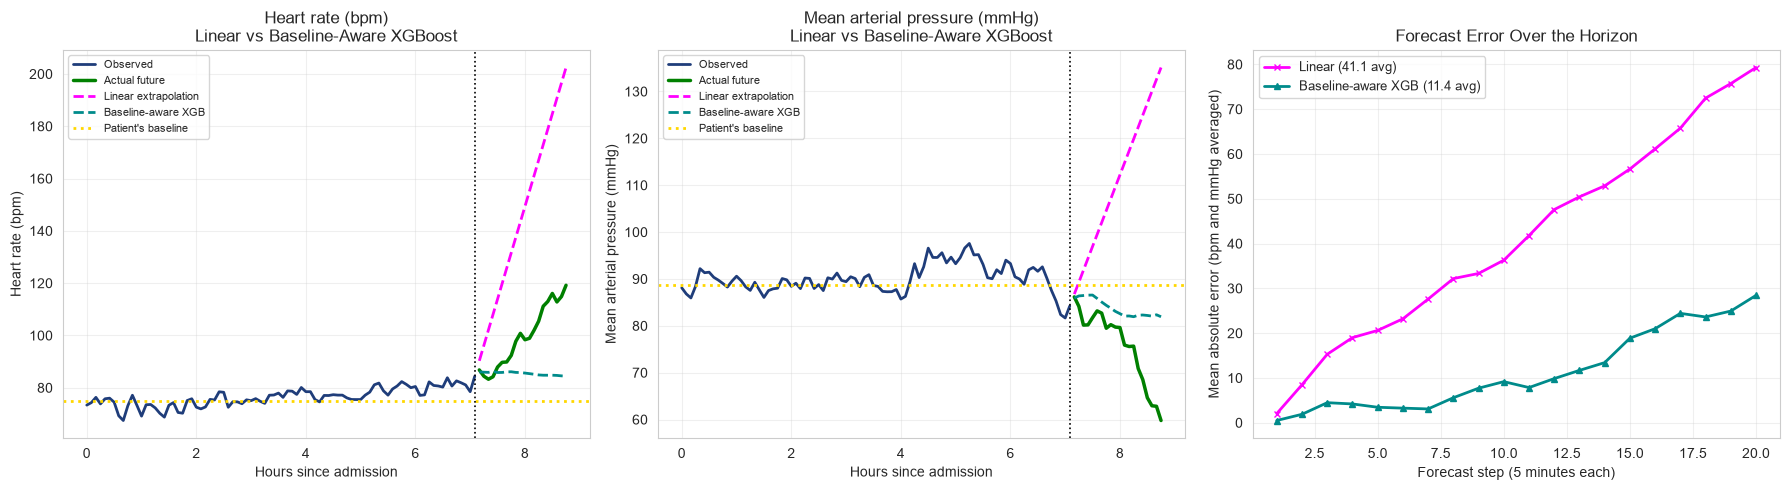


FINAL COMPARISON
Method                       HR MAE (bpm)    MAP MAE (mmHg)    Knows baseline?
------------------------------------------------------------------------------
Linear extrapolation         46.9            35.2              No
Baseline-aware XGBoost       14.6            8.1               Yes

Baseline-aware XGBoost wins
  72% improvement over linear extrapolation

  Key features that made the difference:
    - baseline_heart_rate, baseline_map_mmhg: knows what normal is for this patient
    - gap_to_baseline_*: knows HOW FAR from normal they are
    - recovery_alignment: knows WHETHER they are heading back


In [19]:
# ============================================================================
# Visualize: Linear Extrapolation vs Baseline-Aware XGBoost
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

obs_hours = observed_df['hours_since_admission'].values
fut_hours = actual_future_df['hours_since_admission'].values

# Plots 1 and 2: the two forecast channels
for ax, idx, channel, unit in [(axes[0], 0, 'heart_rate', 'bpm'),
                                (axes[1], 1, 'map_mmhg', 'mmHg')]:
    ax.plot(obs_hours, observed_df[channel].values, '-', color='#1f3d7a',
            linewidth=2, label='Observed')
    ax.plot(fut_hours, actual_future[:, idx], '-', color='green',
            linewidth=2.5, label='Actual future')
    ax.plot(fut_hours, linear_pred[:, idx], '--', color='magenta', linewidth=2,
            label='Linear extrapolation')
    ax.plot(fut_hours, base_aware_pred[:, idx], '--', color='darkcyan', linewidth=2,
            label='Baseline-aware XGB')
    ax.axhline(observed_df[f'baseline_{channel}'].iloc[0], color='gold', linewidth=2,
               linestyle=':', label="Patient's baseline")
    ax.axvline(obs_hours[-1], color='black', linestyle=':', linewidth=1.2)
    ax.set_xlabel('Hours since admission')
    ax.set_ylabel(CHANNEL_LABELS[channel])
    ax.set_title(f'{CHANNEL_LABELS[channel]}\nLinear vs Baseline-Aware XGBoost')
    ax.legend(loc='best', fontsize=8)
    ax.grid(alpha=0.3)

# Plot 3: error over the forecast horizon
ax = axes[2]
steps = range(1, n_pred_steps + 1)
ax.plot(steps, linear_errors, '-x', color='magenta', linewidth=2, markersize=5,
        label=f'Linear ({linear_errors.mean():.1f} avg)')
ax.plot(steps, base_aware_errors, '-^', color='darkcyan', linewidth=2, markersize=5,
        label=f'Baseline-aware XGB ({base_aware_errors.mean():.1f} avg)')
ax.set_xlabel('Forecast step (5 minutes each)')
ax.set_ylabel('Mean absolute error (bpm and mmHg averaged)')
ax.set_title('Forecast Error Over the Horizon')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Summary table
print("\n" + "=" * 78)
print("FINAL COMPARISON")
print("=" * 78)
print(f"{'Method':<28} {'HR MAE (bpm)':<15} {'MAP MAE (mmHg)':<17} {'Knows baseline?'}")
print("-" * 78)
print(f"{'Linear extrapolation':<28} {linear_hr_err.mean():<15.1f} {linear_map_err.mean():<17.1f} {'No'}")
print(f"{'Baseline-aware XGBoost':<28} {base_hr_err.mean():<15.1f} {base_map_err.mean():<17.1f} {'Yes'}")
print("=" * 78)

# Determine winner
if base_aware_errors.mean() < linear_errors.mean():
    improvement = (1 - base_aware_errors.mean() / linear_errors.mean()) * 100
    print(f"\nBaseline-aware XGBoost wins")
    print(f"  {improvement:.0f}% improvement over linear extrapolation")
    print(f"\n  Key features that made the difference:")
    print(f"    - baseline_heart_rate, baseline_map_mmhg: knows what normal is for this patient")
    print(f"    - gap_to_baseline_*: knows HOW FAR from normal they are")
    print(f"    - recovery_alignment: knows WHETHER they are heading back")
else:
    print(f"\n  Linear extrapolation performed better on this stay.")
    print(f"  This happens when the trend simply continues over the forecast window.")


## 11. LSTM Sequence Model for Vitals Forecasting

The XGBoost model predicts each step independently - it has no "memory" of the shape of the
trajectory. An **LSTM (Long Short-Term Memory)** network can learn sequential patterns such as:

- *"After a heart rate has climbed for 30 minutes, it usually keeps climbing"*
- *"Once pressure stops falling and the rate of change flattens, recovery has begun"*
- *"Post-operative patients settle on a decaying curve, not a straight line"*

### Key Differences from XGBoost

| Aspect | XGBoost | LSTM |
|--------|---------|------|
| Input | Single timestep features | Sequence of N monitor samples |
| Memory | None (stateless) | Learns temporal patterns |
| Output | Next step only | Can forecast several steps at once |
| Training | Fast, tabular | Slower, benefits from a GPU |

### Our Approach

1. **Input**: the last N monitor samples, as channel values, rates of change and baseline gaps
2. **Architecture**: LSTM encoder -> dense layers -> forecast the next M changes
3. **Baseline awareness**: the gap to the patient's baseline is included at every timestep

In [20]:
# ============================================================================
# LSTM Setup and Imports
# ============================================================================
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Check for GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

# Sequence parameters
SEQ_LENGTH = 12      # Number of past monitor samples to use as input (1 hour)
PRED_LENGTH = 6      # Number of future samples to forecast (30 minutes)
BATCH_SIZE = 32
EPOCHS = 50
LEARNING_RATE = 0.001

print(f"\nSequence configuration:")
print(f"  Input sequence length: {SEQ_LENGTH} samples ({SEQ_LENGTH * SAMPLE_MINUTES} minutes)")
print(f"  Forecast horizon: {PRED_LENGTH} samples ({PRED_LENGTH * SAMPLE_MINUTES} minutes)")
print(f"  Batch size: {BATCH_SIZE}")


Using device: mps

Sequence configuration:
  Input sequence length: 12 samples (60 minutes)
  Forecast horizon: 6 samples (30 minutes)
  Batch size: 32


In [21]:
# ============================================================================
# Prepare Sequence Data for the LSTM
# ============================================================================

def create_sequences(df, seq_length, pred_length):
    """
    Create input/output sequences for LSTM training.

    KEY INSIGHT: use features that are CONSISTENT across patients:
    - The gap to the patient's own baseline (scale-free per patient)
    - Rates of change (scale-invariant)
    - The other channels, standardized to roughly unit scale

    DO NOT use raw channel values as inputs - every patient sits at a different
    level, and the model would spend its capacity memorizing those levels.

    Returns:
        X: (num_sequences, seq_length, num_features)
        y: (num_sequences, pred_length, 2)  # step-by-step changes in HR and MAP
    """
    sequences_X = []
    sequences_y = []

    for pid in df['patient_id'].unique():
        patient_df = df[df['patient_id'] == pid].reset_index(drop=True)

        if len(patient_df) < seq_length + pred_length:
            continue

        # Precompute the arrays we need, so the sliding window is cheap
        gap_hr = (patient_df['heart_rate'] - patient_df['baseline_heart_rate']).values
        gap_map = (patient_df['map_mmhg'] - patient_df['baseline_map_mmhg']).values
        d_hr = patient_df['d_heart_rate'].values
        d_map = patient_df['d_map_mmhg'].values
        spo2 = patient_df['spo2'].values
        resp = patient_df['resp_rate'].values
        temp = patient_df['temp_c'].values
        vol_hr = patient_df['roll_std_heart_rate'].values
        vol_map = patient_df['roll_std_map_mmhg'].values
        progress = patient_df['stay_progress'].values
        hr = patient_df['heart_rate'].values
        mp = patient_df['map_mmhg'].values

        # Create sliding window sequences
        for i in range(len(patient_df) - seq_length - pred_length + 1):
            input_seq = []
            for j in range(seq_length):
                k = i + j

                # Features that are CONSISTENT across all patients:
                timestep = [
                    gap_hr[k] / 30.0,        # Gap to baseline, scaled
                    gap_map[k] / 20.0,
                    d_hr[k],                 # Rate of change (already small)
                    d_map[k],
                    (spo2[k] - 97.0) / 3.0,  # Other channels, centred and scaled
                    (resp[k] - 16.0) / 5.0,
                    (temp[k] - 37.0) / 1.0,
                    vol_hr[k] / 3.0,         # Volatility
                    vol_map[k] / 3.0,
                    progress[k],             # Stay progress
                ]
                input_seq.append(timestep)

            # Output: step-by-step changes over the forecast horizon
            output_seq = []
            for j in range(pred_length):
                k = i + seq_length + j
                output_seq.append([hr[k] - hr[k - 1], mp[k] - mp[k - 1]])

            sequences_X.append(input_seq)
            sequences_y.append(output_seq)

    return np.array(sequences_X, dtype=np.float32), np.array(sequences_y, dtype=np.float32)

# Create sequences
print("Creating sequences from the monitoring data...")
print("(Using patient-INDEPENDENT features: gap to baseline, rates of change, volatility)")
X_seq, y_seq = create_sequences(df_features, SEQ_LENGTH, PRED_LENGTH)

print(f"\nCreated {len(X_seq):,} sequences")
print(f"  Input shape:  {X_seq.shape} (samples, timesteps, features)")
print(f"  Output shape: {y_seq.shape} (samples, horizon, channel changes)")
print(f"  Features per timestep: {X_seq.shape[2]}")

# Train/test split
from sklearn.model_selection import train_test_split
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_seq, y_seq, test_size=0.2, random_state=42
)

print(f"\n  Training sequences: {len(X_train_seq):,}")
print(f"  Test sequences: {len(X_test_seq):,}")


Creating sequences from the monitoring data...
(Using patient-INDEPENDENT features: gap to baseline, rates of change, volatility)



Created 32,520 sequences
  Input shape:  (32520, 12, 10) (samples, timesteps, features)
  Output shape: (32520, 6, 2) (samples, horizon, channel changes)
  Features per timestep: 10

  Training sequences: 26,016
  Test sequences: 6,504


In [22]:
# ============================================================================
# Define the LSTM Model Architecture
# ============================================================================

class VitalsPredictor(nn.Module):
    """
    LSTM-based vitals forecasting model.

    Architecture:
        Input (seq_length, features)
        -> LSTM layers (learn temporal patterns)
        -> Dense layers (decode to forecasts)
        -> Output (pred_length, 2)  # change in heart rate and pressure per step
    """
    def __init__(self, input_size, hidden_size=64, num_layers=2, pred_length=6, dropout=0.2):
        super(VitalsPredictor, self).__init__()

        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.pred_length = pred_length

        # LSTM encoder - processes the input sequence
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        # Decoder - transforms the LSTM output into forecasts
        self.decoder = nn.Sequential(
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, hidden_size // 2),
            nn.ReLU(),
            nn.Linear(hidden_size // 2, pred_length * 2)  # pred_length * (HR, MAP)
        )

    def forward(self, x):
        # x shape: (batch, seq_length, features)

        # LSTM forward pass
        lstm_out, (h_n, c_n) = self.lstm(x)

        # Use the last hidden state for the forecast
        # h_n shape: (num_layers, batch, hidden_size)
        last_hidden = h_n[-1]  # (batch, hidden_size)

        # Decode to forecasts
        output = self.decoder(last_hidden)  # (batch, pred_length * 2)

        # Reshape to (batch, pred_length, 2)
        output = output.view(-1, self.pred_length, 2)

        return output

# Create model
input_features = X_seq.shape[2]
model = VitalsPredictor(
    input_size=input_features,
    hidden_size=128,
    num_layers=2,
    pred_length=PRED_LENGTH,
    dropout=0.2
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Vitals Predictor LSTM Model")
print("=" * 50)
print(model)
print("=" * 50)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Vitals Predictor LSTM Model
VitalsPredictor(
  (lstm): LSTM(10, 128, num_layers=2, batch_first=True, dropout=0.2)
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Linear(in_features=64, out_features=12, bias=True)
  )
)
Total parameters: 229,324
Trainable parameters: 229,324


In [23]:
# ============================================================================
# Create DataLoaders and Train the LSTM
# ============================================================================

class VitalsSequenceDataset(Dataset):
    """PyTorch Dataset for vitals sequences."""
    def __init__(self, X, y):
        self.X = torch.FloatTensor(X)
        self.y = torch.FloatTensor(y)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

# Create datasets and dataloaders
train_dataset = VitalsSequenceDataset(X_train_seq, y_train_seq)
test_dataset = VitalsSequenceDataset(X_test_seq, y_test_seq)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

# Loss and optimizer
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5)

# Training loop
print("Training the LSTM vitals predictor...")
print("=" * 60)

train_losses = []
test_losses = []
best_test_loss = float('inf')

for epoch in range(EPOCHS):
    # Training
    model.train()
    train_loss = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)
        loss.backward()

        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()
        train_loss += loss.item()

    train_loss /= len(train_loader)
    train_losses.append(train_loss)

    # Evaluation
    model.eval()
    test_loss = 0.0
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            predictions = model(X_batch)
            loss = criterion(predictions, y_batch)
            test_loss += loss.item()

    test_loss /= len(test_loader)
    test_losses.append(test_loss)

    # Update learning rate
    scheduler.step(test_loss)

    # Save best model
    if test_loss < best_test_loss:
        best_test_loss = test_loss
        best_model_state = model.state_dict().copy()

    # Print progress every 10 epochs
    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch+1:3d}/{EPOCHS} | Train Loss: {train_loss:.6f} | Test Loss: {test_loss:.6f}")

# Load best model
model.load_state_dict(best_model_state)
print("=" * 60)
print(f"Training complete. Best test loss: {best_test_loss:.6f}")


Training the LSTM vitals predictor...


Epoch  10/50 | Train Loss: 4.967901 | Test Loss: 4.958578


Epoch  20/50 | Train Loss: 4.354041 | Test Loss: 4.566271


Epoch  30/50 | Train Loss: 3.844579 | Test Loss: 4.266984


Epoch  40/50 | Train Loss: 3.470262 | Test Loss: 4.040433


Epoch  50/50 | Train Loss: 3.208212 | Test Loss: 3.863670
Training complete. Best test loss: 3.863670


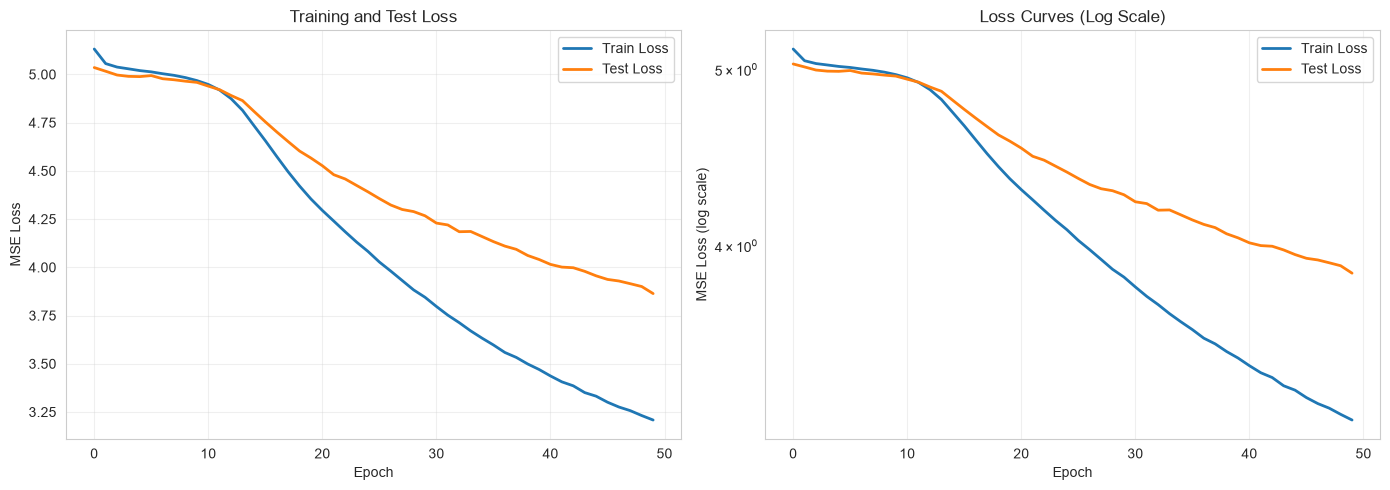

Final training loss: 3.208212
Final test loss: 3.863670
Best test loss: 3.863670


In [24]:
# ============================================================================
# Visualize Training Progress
# ============================================================================

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Loss curves
ax = axes[0]
ax.plot(train_losses, label='Train Loss', linewidth=2)
ax.plot(test_losses, label='Test Loss', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('Training and Test Loss')
ax.legend()
ax.grid(alpha=0.3)

# Plot 2: Learning rate schedule effect (loss reduction)
ax = axes[1]
ax.semilogy(train_losses, label='Train Loss', linewidth=2)
ax.semilogy(test_losses, label='Test Loss', linewidth=2)
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss (log scale)')
ax.set_title('Loss Curves (Log Scale)')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Final training loss: {train_losses[-1]:.6f}")
print(f"Final test loss: {test_losses[-1]:.6f}")
print(f"Best test loss: {best_test_loss:.6f}")

In [25]:
# ============================================================================
# Compare the LSTM with XGBoost on a Full Trajectory Forecast
# ============================================================================

def predict_with_lstm(model, patient_df, seq_length, pred_steps):
    """
    Use the LSTM to forecast a vitals trajectory given the observed history.

    Uses patient-INDEPENDENT features (gap to baseline, rates of change), so the
    same model works for a patient with a resting heart rate of 60 and one at 95.
    """
    model.eval()

    baseline_hr = patient_df['baseline_heart_rate'].iloc[0]
    baseline_map = patient_df['baseline_map_mmhg'].iloc[0]

    # Running history of (hr, map), seeded with the observed window
    hist_hr = list(patient_df['heart_rate'].values)
    hist_map = list(patient_df['map_mmhg'].values)
    hist_spo2 = list(patient_df['spo2'].values)
    hist_resp = list(patient_df['resp_rate'].values)
    hist_temp = list(patient_df['temp_c'].values)
    hist_progress = list(patient_df['stay_progress'].values)

    predictions = []

    while len(predictions) < pred_steps:
        input_seq = []
        for j in range(seq_length, 0, -1):
            k = len(hist_hr) - j
            d_hr = hist_hr[k] - hist_hr[k - 1] if k > 0 else 0.0
            d_map = hist_map[k] - hist_map[k - 1] if k > 0 else 0.0

            # Rolling volatility over the last six samples we know about
            lo = max(0, k - 5)
            vol_hr = float(np.std(hist_hr[lo:k + 1])) if k > lo else 0.0
            vol_map = float(np.std(hist_map[lo:k + 1])) if k > lo else 0.0

            input_seq.append([
                (hist_hr[k] - baseline_hr) / 30.0,
                (hist_map[k] - baseline_map) / 20.0,
                d_hr,
                d_map,
                (hist_spo2[k] - 97.0) / 3.0,
                (hist_resp[k] - 16.0) / 5.0,
                (hist_temp[k] - 37.0) / 1.0,
                vol_hr / 3.0,
                vol_map / 3.0,
                hist_progress[k],
            ])

        X = torch.FloatTensor([input_seq]).to(device)
        with torch.no_grad():
            pred = model(X).cpu().numpy()[0]

        # Accumulate the step-by-step changes
        for i in range(len(pred)):
            next_hr = hist_hr[-1] + pred[i, 0]
            next_map = hist_map[-1] + pred[i, 1]
            predictions.append((next_hr, next_map))

            # Extend the history so the next window can be built
            hist_hr.append(next_hr)
            hist_map.append(next_map)
            hist_spo2.append(hist_spo2[-1])
            hist_resp.append(hist_resp[-1])
            hist_temp.append(hist_temp[-1])
            hist_progress.append(min(1.0, hist_progress[-1] + 1.0 / 288))

            if len(predictions) >= pred_steps:
                break

    return np.array(predictions[:pred_steps])

# Find a test trajectory: a patient who actually deteriorates
print("Comparing the LSTM with XGBoost on a test trajectory...\n")

deteriorating_ids = df_base.loc[
    df_base['archetype'].isin(['sepsis_deterioration', 'cardiac_event']), 'patient_id'
].unique()

for pid in deteriorating_ids:
    test_patient_df = df_base[df_base['patient_id'] == pid].reset_index(drop=True)
    if len(test_patient_df) >= 60:
        break

# Start the forecast just before the onset of deterioration, so the models have
# to forecast through the turn - the clinically interesting failure case.
onset_rows = test_patient_df.index[test_patient_df['deteriorating'] == 1]
if len(onset_rows) > 0:
    split_idx = max(SEQ_LENGTH + 1, int(onset_rows[0]) - 4)
else:
    split_idx = SEQ_LENGTH + 5
split_idx = min(split_idx, len(test_patient_df) - 21)

observed_df = test_patient_df.iloc[:split_idx].copy()
n_predict = min(20, len(test_patient_df) - split_idx)
actual_future = test_patient_df.iloc[split_idx:split_idx + n_predict][['heart_rate', 'map_mmhg']].values

print(f"Test patient: {pid}")
print(f"Archetype: {ARCHETYPES[test_patient_df['archetype'].iloc[0]]['label']}")
print(f"Observed readings: {len(observed_df)}")
print(f"Forecasting: {n_predict} future steps ({n_predict * SAMPLE_MINUTES} minutes)")

# 1. LSTM forecast
lstm_pred = predict_with_lstm(model, observed_df, SEQ_LENGTH, n_predict)

# 2. Baseline-aware XGBoost forecast
xgb_pred = forecast_baseline_aware(
    xgb_base_hr, xgb_base_map,
    observed_df.iloc[-1].copy(),
    n_steps=n_predict
)
xgb_pred = np.array(xgb_pred)

# 3. Linear extrapolation
linear_pred = []
last_d_hr = observed_df['d_heart_rate'].iloc[-1]
last_d_map = observed_df['d_map_mmhg'].iloc[-1]
curr_hr, curr_map = observed_df['heart_rate'].iloc[-1], observed_df['map_mmhg'].iloc[-1]
for _ in range(n_predict):
    curr_hr += last_d_hr
    curr_map += last_d_map
    linear_pred.append((curr_hr, curr_map))
linear_pred = np.array(linear_pred)

# Calculate errors
lstm_hr_err, lstm_map_err, lstm_errors = forecast_error(lstm_pred, actual_future)
xgb_hr_err, xgb_map_err, xgb_errors = forecast_error(xgb_pred, actual_future)
lin_hr_err, lin_map_err, linear_errors = forecast_error(linear_pred, actual_future)

print(f"\nAverage forecast errors:")
print(f"  Linear extrapolation:     {lin_hr_err.mean():.1f} bpm / {lin_map_err.mean():.1f} mmHg")
print(f"  Baseline-aware XGBoost:   {xgb_hr_err.mean():.1f} bpm / {xgb_map_err.mean():.1f} mmHg")
print(f"  LSTM sequence model:      {lstm_hr_err.mean():.1f} bpm / {lstm_map_err.mean():.1f} mmHg")


Comparing the LSTM with XGBoost on a test trajectory...

Test patient: P0002
Archetype: Sepsis deterioration
Observed readings: 115
Forecasting: 20 future steps (100 minutes)

Average forecast errors:
  Linear extrapolation:     27.8 bpm / 12.1 mmHg
  Baseline-aware XGBoost:   4.6 bpm / 2.2 mmHg
  LSTM sequence model:      3.0 bpm / 2.4 mmHg


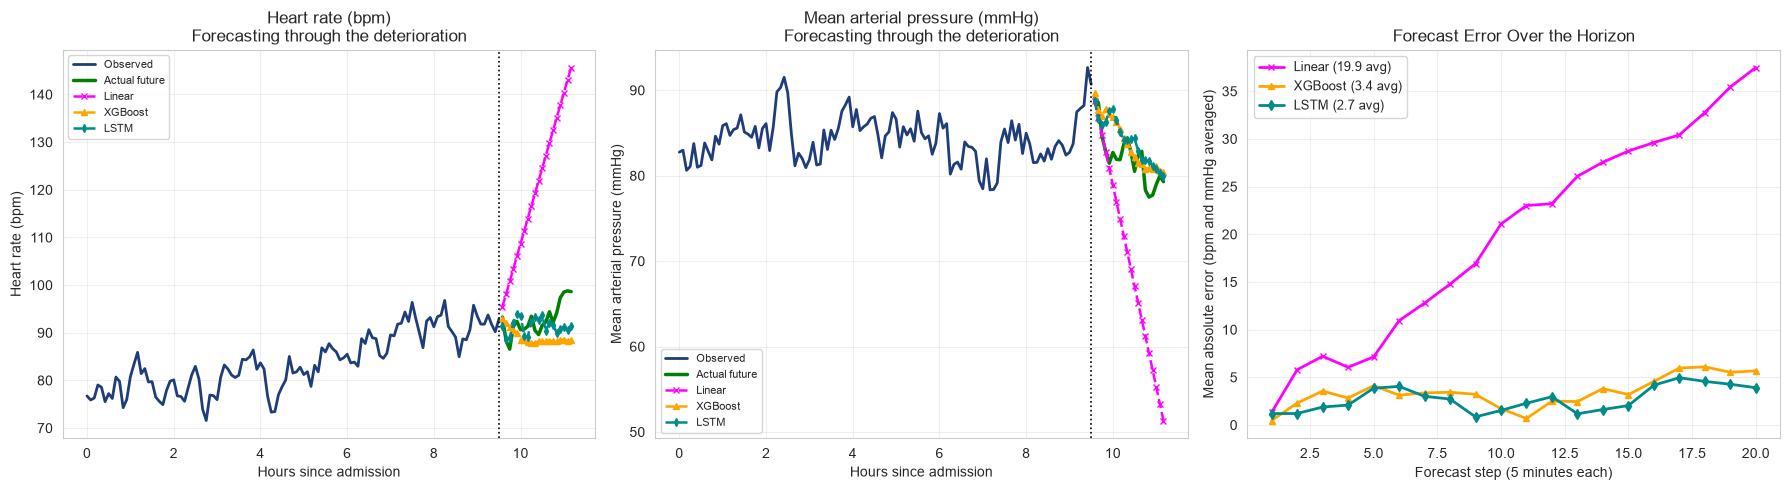


FINAL MODEL COMPARISON
Method                       HR MAE (bpm)    MAP MAE (mmHg)    Memory
------------------------------------------------------------------------------
Linear extrapolation         27.8            12.1              No
Baseline-aware XGBoost       4.6             2.2               No
LSTM sequence model          3.0             2.4               Yes

Best model: LSTM with a combined mean absolute error of 2.7


In [26]:
# ============================================================================
# Visualize the LSTM vs XGBoost Comparison
# ============================================================================

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

obs_hours = observed_df['hours_since_admission'].values
fut_hours = test_patient_df.iloc[split_idx:split_idx + n_predict]['hours_since_admission'].values

# Plots 1 and 2: the two forecast channels
for ax, idx, channel in [(axes[0], 0, 'heart_rate'), (axes[1], 1, 'map_mmhg')]:
    ax.plot(obs_hours, observed_df[channel].values, '-', color='#1f3d7a', linewidth=2,
            label='Observed')
    ax.plot(fut_hours, actual_future[:, idx], '-', color='green', linewidth=2.5,
            label='Actual future')
    ax.plot(fut_hours, linear_pred[:, idx], '--x', color='magenta', linewidth=1.8,
            markersize=4, label='Linear')
    ax.plot(fut_hours, xgb_pred[:, idx], '--^', color='orange', linewidth=1.8,
            markersize=4, label='XGBoost')
    ax.plot(fut_hours, lstm_pred[:, idx], '--d', color='darkcyan', linewidth=1.8,
            markersize=4, label='LSTM')
    ax.axvline(obs_hours[-1], color='black', linestyle=':', linewidth=1.2)
    ax.set_xlabel('Hours since admission')
    ax.set_ylabel(CHANNEL_LABELS[channel])
    ax.set_title(f'{CHANNEL_LABELS[channel]}\nForecasting through the deterioration')
    ax.legend(loc='best', fontsize=8)
    ax.grid(alpha=0.3)

# Plot 3: error over the forecast horizon
ax = axes[2]
steps = range(1, len(lstm_errors) + 1)
ax.plot(steps, linear_errors, '-x', color='magenta', linewidth=2, markersize=5,
        label=f'Linear ({linear_errors.mean():.1f} avg)')
ax.plot(steps, xgb_errors, '-^', color='orange', linewidth=2, markersize=5,
        label=f'XGBoost ({xgb_errors.mean():.1f} avg)')
ax.plot(steps, lstm_errors, '-d', color='darkcyan', linewidth=2, markersize=5,
        label=f'LSTM ({lstm_errors.mean():.1f} avg)')
ax.set_xlabel('Forecast step (5 minutes each)')
ax.set_ylabel('Mean absolute error (bpm and mmHg averaged)')
ax.set_title('Forecast Error Over the Horizon')
ax.legend(fontsize=9)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Summary table
print("\n" + "=" * 78)
print("FINAL MODEL COMPARISON")
print("=" * 78)
print(f"{'Method':<28} {'HR MAE (bpm)':<15} {'MAP MAE (mmHg)':<17} {'Memory'}")
print("-" * 78)
print(f"{'Linear extrapolation':<28} {lin_hr_err.mean():<15.1f} {lin_map_err.mean():<17.1f} {'No'}")
print(f"{'Baseline-aware XGBoost':<28} {xgb_hr_err.mean():<15.1f} {xgb_map_err.mean():<17.1f} {'No'}")
print(f"{'LSTM sequence model':<28} {lstm_hr_err.mean():<15.1f} {lstm_map_err.mean():<17.1f} {'Yes'}")
print("=" * 78)

# Determine winner
methods = [
    ('Linear', linear_errors.mean()),
    ('XGBoost', xgb_errors.mean()),
    ('LSTM', lstm_errors.mean())
]
best = min(methods, key=lambda x: x[1])
print(f"\nBest model: {best[0]} with a combined mean absolute error of {best[1]:.1f}")


### LSTM Key Takeaways

**What the LSTM adds over XGBoost:**
- **Sequence memory**: learns patterns such as "once the rate of rise flattens, the peak is near"
- **Multi-step forecasting**: produces several future samples at once
- **Trajectory shape awareness**: distinguishes a settling curve from a runaway one

**When the LSTM helps most:**
- Forecasting through a turning point - the onset of deterioration, or the start of recovery
- Trajectories with a consistent shape, like post-operative settling
- Longer horizons, where error accumulation matters

**Trade-offs:**
| Aspect | XGBoost | LSTM |
|--------|---------|------|
| Training time | Fast (seconds) | Slower (minutes) |
| Interpretability | Feature importance | Black box |
| Data requirements | Works with less data | Needs many sequences |
| Hardware | CPU only | Benefits from a GPU |

**Practical recommendation:**
- **Short horizon (1-5 steps, up to 25 minutes)**: XGBoost is usually enough and much faster
- **Medium horizon (5-20 steps, up to 100 minutes)**: the LSTM's sequence memory earns its keep
- **Long horizon (20+ steps)**: consider a dedicated forecasting architecture - see the Tiny Time
  Mixer notebook, which forecasts 32 steps from 128 steps of context

**A clinical caution:** a forecast is not an alarm. These models suggest where a patient is
heading; the decision to escalate stays with the care team.

In [27]:
# Export trained models for deployment
import pickle

models_dir = Path('../../models/vitals_forecasting')
models_dir.mkdir(parents=True, exist_ok=True)

# Save next-reading models
with open(models_dir / 'xgb_heart_rate_model.pkl', 'wb') as f:
    pickle.dump(xgb_hr, f)

with open(models_dir / 'xgb_map_model.pkl', 'wb') as f:
    pickle.dump(xgb_map, f)

# Save rate-of-change models (for long-horizon forecasting)
with open(models_dir / 'xgb_delta_heart_rate_model.pkl', 'wb') as f:
    pickle.dump(xgb_delta_hr, f)

with open(models_dir / 'xgb_delta_map_model.pkl', 'wb') as f:
    pickle.dump(xgb_delta_map, f)

# Save the disposition classifier
with open(models_dir / 'xgb_disposition_classifier.pkl', 'wb') as f:
    pickle.dump(xgb_clf, f)

# Save encoders
with open(models_dir / 'disposition_encoder.pkl', 'wb') as f:
    pickle.dump(le_disposition, f)

print("Models saved successfully to:", models_dir)
print("\nSaved models:")
print("  Next-reading models (short horizon):")
print("    - xgb_heart_rate_model.pkl")
print("    - xgb_map_model.pkl")
print("\n  Rate-of-change models (long horizon):")
print("    - xgb_delta_heart_rate_model.pkl")
print("    - xgb_delta_map_model.pkl")
print("\n  Classification:")
print("    - xgb_disposition_classifier.pkl")
print("\n  Encoders:")
print("    - disposition_encoder.pkl")


Models saved successfully to: ../../models/vitals_forecasting

Saved models:
  Next-reading models (short horizon):
    - xgb_heart_rate_model.pkl
    - xgb_map_model.pkl

  Rate-of-change models (long horizon):
    - xgb_delta_heart_rate_model.pkl
    - xgb_delta_map_model.pkl

  Classification:
    - xgb_disposition_classifier.pkl

  Encoders:
    - disposition_encoder.pkl
